# LLFormer — Full Training Notebook (Config A, B, C, D)
### Ablation Study: Loss-Based Enhancement on LOL-v1 Dataset

> **PROTOCOL v2** (xem PROTOCOL.md). Hyper-parameter vẫn theo **TABLE III** (CosineAnnealingLR, Smooth L1 δ=1.0, LR 1.5e-4→1e-6, no warmup / no grad clip), nhưng:  
> seed **0/1/2**, báo cáo **checkpoint epoch cuối** (không chọn epoch trên eval15), đánh giá bằng `eval.py` (uint8, 2 biến thể SSIM), kết quả = mean ± std qua seed.  
> Notebook chạy **A → B → C → D**, mỗi (config, seed) khởi tạo model từ epoch 0. **Chạy Section 7B + 7C (loss sanity + smoke test) và PASS trước khi train thật.**

---
| Section | Nội dung |
|---------|----------|
| **1** | Environment Setup |
| **2** | Clone LLFormer Repository |
| **3** | Dataset Download / Mount Drive |
| **4** | Dataset Extraction and Validation |
| **5** | Dependency Installation |
| **6** | Source Code Validation |
| **7** | Model and Loss Verification |
| **7B / 7C** | Loss sanity + Smoke test A–D / eval / tái lập / resume (bắt buộc) |
| **8** | Config A Training (Baseline — Smooth L1) |
| **9** | Config B Training |
| **10** | Config C Training |
| **11** | Config D Training |
| **12** | Results Comparison |
| **13** | Export Checkpoints and Logs |

**Phải chạy tuần tự Section 1–7 trước khi bắt đầu training.**

**Thu tu bat buoc:** Section 1 → 2 (clone + cell 2F inject) → 3 → 4 → **5 (pip)** → 6 → 7 → train A/B/C/D.
Khong bo qua Section 5 truoc khi chay Section 6/7.


## Section 1: Environment Setup

In [ ]:
import os, sys, platform, datetime, subprocess
import torch

# ── 1A. GPU check ──────────────────────────────────────────────────────────
CUDA = torch.cuda.is_available()
DEVICE = torch.device('cuda:0' if CUDA else 'cpu')

print('=' * 65)
print('  ENVIRONMENT CHECK')
print('=' * 65)
print(f'  Python          : {sys.version.split()[0]}')
print(f'  Platform        : {platform.platform()}')
print(f'  PyTorch         : {torch.__version__}')
print(f'  CUDA available  : {CUDA}')
if CUDA:
    print(f'  CUDA version    : {torch.version.cuda}')
    print(f'  GPU name        : {torch.cuda.get_device_name(0)}')
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'  GPU VRAM        : {vram_gb:.2f} GB')
print('=' * 65)

if not CUDA:
    raise RuntimeError(
        'CUDA khong kha dung!\n'
        'Vao Runtime > Change runtime type > chon T4 GPU roi chay lai.'
    )

# ── 1B. Mount Google Drive (de luu checkpoint ben vung) ────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/LLFormer1/LLFormer_Colab'
    os.makedirs(DRIVE_ROOT, exist_ok=True)
    SAVE_TO_DRIVE = True
    print(f'Drive mounted. Checkpoints se luu tai: {DRIVE_ROOT}')
except Exception as _e:
    DRIVE_ROOT = None
    SAVE_TO_DRIVE = False
    print(f'Khong mount duoc Drive ({_e}). Checkpoint chi luu local.')
    print('Neu runtime bi ngat, checkpoint se mat. Nen mount Drive truoc.')

  ENVIRONMENT CHECK
  Python          : 3.13.16
  Platform        : Linux-6.6.159+-x86_64-with-glibc2.39
  PyTorch         : 2.14.1+cu130
  CUDA available  : True
  CUDA version    : 13.0
  GPU name        : Tesla T4
  GPU VRAM        : 15.64 GB
Mounted at /content/drive
Drive mounted. Checkpoints se luu tai: /content/drive/MyDrive/LLFormer1/LLFormer_Colab


## Section 2: Clone LLFormer Repository

Clone repository chính thức từ GitHub và copy các file bổ sung (`train_unified.py`, `losses/`) từ Google Drive nếu có.

> **Lưu ý:** Repository gốc tại `https://github.com/TaoWangzj/LLFormer` chứa kiến trúc model, data loaders và utils gốc.  
> Các file `train_unified.py` và `losses/` là phần mở rộng của nhóm (chứa loss B/C/D),  
> phải được cung cấp qua Google Drive hoặc upload trực tiếp vào Colab.

In [ ]:
import os, sys, shutil, subprocess

PROJECT_ROOT = '/content/LLFormer'

# ── 2A. Clone repo chinh thuc neu chua co ──────────────────────────────────
if not os.path.exists(os.path.join(PROJECT_ROOT, 'model', 'LLFormer.py')):
    print('Cloning LLFormer from GitHub...')
    subprocess.run(
        ['git', 'clone', '--depth=1', '-q',
         'https://github.com/TaoWangzj/LLFormer.git', PROJECT_ROOT],
        check=True
    )
    print('[OK] Clone thanh cong.')
else:
    print('[OK] Repository da ton tai tai', PROJECT_ROOT)

# ── 2B. Them PROJECT_ROOT vao sys.path ─────────────────────────────────────
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)
print(f'Working directory: {os.getcwd()}')

# ── 2C. Kiem tra cau truc co ban ──────────────────────────────────────────
base_required = [
    'model/LLFormer.py',
    'transform/dataset_RGB.py',
    'transform/data_RGB.py',
    'utils/__init__.py',
    'utils/losses.py',
]
missing_base = [f for f in base_required if not os.path.exists(f)]
if missing_base:
    raise FileNotFoundError(
        f'Cau truc repo thieu file:\n' + '\n'.join(f'  - {f}' for f in missing_base)
    )
print('[OK] Cau truc repo co ban hop le.')

# ── 2D. Copy train_unified.py va losses/ tu Drive (neu co) ────────────────
EXTRA_FILES_NEEDED = ['train_unified.py', 'losses/hsv_loss.py',
                      'losses/lab_loss.py', 'losses/joint_loss.py',
                      'losses/__init__.py']
missing_extra = [f for f in EXTRA_FILES_NEEDED if not os.path.exists(f)]

if missing_extra and SAVE_TO_DRIVE:
    drive_src = os.path.join(DRIVE_ROOT, 'LLFormer_Colab_Source.zip')
    if os.path.exists(drive_src):
        import zipfile
        print(f'Giai nen source code tu {drive_src}...')
        with zipfile.ZipFile(drive_src) as zf:
            zf.extractall(PROJECT_ROOT)
        print('[OK] Giai nen source code.')
    else:
        print('[WARN] Khong tim thay LLFormer_Colab_Source.zip tren Drive.')

# Re-check
missing_extra = [f for f in EXTRA_FILES_NEEDED if not os.path.exists(f)]
if missing_extra:
    print('\n[WARN] Cac file sau chua co (se duoc ghi de o cell TABLE III ngay sau):')
    for f in missing_extra:
        print(f'  - {PROJECT_ROOT}/{f}')
else:
    print('[OK] Tat ca file source code da co day du (se van ghi de TABLE III o cell tiep theo).')

# Tao __init__.py cho losses/ neu thieu
losses_init = os.path.join(PROJECT_ROOT, 'losses', '__init__.py')
os.makedirs(os.path.dirname(losses_init), exist_ok=True)
if not os.path.exists(losses_init):
    open(losses_init, 'w').close()
print('[OK] losses/__init__.py OK')


Cloning LLFormer from GitHub...
[OK] Clone thanh cong.
Working directory: /content/LLFormer
[OK] Cau truc repo co ban hop le.
[WARN] Khong tim thay LLFormer_Colab_Source.zip tren Drive.

[WARN] Cac file sau chua co (se duoc ghi de o cell TABLE III ngay sau):
  - /content/LLFormer/train_unified.py
  - /content/LLFormer/losses/hsv_loss.py
  - /content/LLFormer/losses/lab_loss.py
  - /content/LLFormer/losses/joint_loss.py
  - /content/LLFormer/losses/__init__.py
[OK] losses/__init__.py OK


In [ ]:
# ── 2F. Ghi de source code khop TABLE III + full-res validation + save_img fix ──
# Chi GIAI NEN file — KHONG import train_unified o day (can cai package truoc o Section 5).
import base64, io, zipfile, os

_TABLE_III_SRC_B64 = '...'

assert 'PROJECT_ROOT' in globals(), 'Chay cell Clone (Section 2) truoc.'

with zipfile.ZipFile(io.BytesIO(base64.b64decode(_TABLE_III_SRC_B64))) as zf:
    zf.extractall(PROJECT_ROOT)

required = [
    'train_unified.py',
    'run_utils.py',
    'eval.py',
    'losses/joint_loss.py',
    'losses/hsv_loss.py',
    'losses/lab_loss.py',
    'losses/__init__.py',
    'transform/data_RGB.py',
    'transform/dataset_RGB.py',
    'utils/image_utils.py',
    'utils/__init__.py',
]
print('[OK] Da ghi de source TABLE III (chi giai nen, chua import):')
for f in required:
    p = os.path.join(PROJECT_ROOT, f)
    assert os.path.isfile(p), f'Missing {p}'
    print(f'  - {f}')
print('[OK] Tiep tuc Section 3–5 (dataset + pip). Section 6 se validate import.')


[OK] Da ghi de source TABLE III (chi giai nen, chua import):
  - train_unified.py
  - run_utils.py
  - eval.py
  - losses/joint_loss.py
  - losses/hsv_loss.py
  - losses/lab_loss.py
  - losses/__init__.py
  - transform/data_RGB.py
  - transform/dataset_RGB.py
  - utils/image_utils.py
  - utils/__init__.py
[OK] Tiep tuc Section 3–5 (dataset + pip). Section 6 se validate import.


In [ ]:
# ── 2E. Upload thu cong neu can (chay neu cell 2D bao loi) ───────────────
# Chay cell nay de upload LLFormer_Colab_Source.zip truc tiep
# Sau do chay lai cell 2C-2D ben tren.
import os
try:
    from google.colab import files
    print('Click nut "Choose Files" de upload LLFormer_Colab_Source.zip')
    uploaded = files.upload()
    for fname in uploaded:
        print(f'Da nhan: {fname} ({len(uploaded[fname])/1024:.1f} KB)')
        dest = os.path.join(PROJECT_ROOT, fname)
        with open(dest, 'wb') as f:
            f.write(uploaded[fname])
    print('Hay chay lai cell 2D de giai nen.')
except Exception as e:
    print(f'Khong chay duoc upload widget: {e}')

Click nut "Choose Files" de upload LLFormer_Colab_Source.zip


Hay chay lai cell 2D de giai nen.


## Section 3: Dataset Download / Mount Drive

Tải LOL-v1 dataset (~347 MB) tự động từ HuggingFace.  
Nếu đã có sẵn trên Drive, sẽ dùng bản đó (tốc độ nhanh hơn).  
Nếu mạng chặn HuggingFace, hướng dẫn upload thủ công được hiển thị bên dưới.

In [ ]:
import os, shutil, zipfile

DATASET_ROOT = os.path.join(PROJECT_ROOT, 'LOLdataset')
TRAIN_DIR    = os.path.join(DATASET_ROOT, 'our485')
VAL_DIR      = os.path.join(DATASET_ROOT, 'eval15')

def dataset_ready():
    for sub in ['our485/low', 'our485/high', 'eval15/low', 'eval15/high']:
        d = os.path.join(DATASET_ROOT, sub)
        if not os.path.isdir(d) or len(os.listdir(d)) < 10:
            return False
    return True

if dataset_ready():
    print('[OK] Dataset da co san.')
else:
    zip_path = None

    # Thu 1: Tim tren Drive
    if SAVE_TO_DRIVE:
        drive_zip = os.path.join(DRIVE_ROOT, 'LOLdataset.zip')
        if os.path.exists(drive_zip):
            zip_path = drive_zip
            print(f'Tim thay dataset tren Drive: {drive_zip}')

    # Thu 2: Tai tu HuggingFace qua pip
    if zip_path is None:
        try:
            print('Dang tai LOL dataset tu HuggingFace (~347 MB)...')
            import subprocess
            subprocess.run(['pip', 'install', '-q', 'huggingface_hub'], check=True)
            from huggingface_hub import hf_hub_download
            zip_path = hf_hub_download(
                repo_id='geekyrakshit/LoL-Dataset',
                filename='lol_dataset.zip',
                repo_type='dataset'
            )
            print(f'[OK] Tai xong: {zip_path}')
        except Exception as e:
            print(f'[WARN] HuggingFace hub that bai: {e}')

    # Thu 3: wget fallback
    if zip_path is None:
        LOCAL_ZIP = '/content/lol_dataset.zip'
        print('Thu wget tu HuggingFace CDN...')
        ret = os.system(
            f'wget -q --show-progress -O {LOCAL_ZIP} '
            f'"https://huggingface.co/datasets/geekyrakshit/LoL-Dataset/resolve/main/lol_dataset.zip"'
        )
        if ret == 0 and os.path.exists(LOCAL_ZIP) and os.path.getsize(LOCAL_ZIP) > 1e8:
            zip_path = LOCAL_ZIP
            print(f'[OK] wget thanh cong.')
        else:
            print('[WARN] wget that bai.')

    if zip_path is None:
        print(
            '\n[FAIL] Khong the tu dong tai dataset.'
            '\n\nHuong dan tai thu cong:'
            '\n  1. Tai LOLdataset.zip tu nguon hop le (Baidu/Google Drive/...):'
            '\n     Chuc nang upload nhanh: chay cell tiep theo de upload.'
            '\n  2. Hoac: copy LOLdataset.zip len Google Drive, '
            '\n     dat vao MyDrive/LLFormer_Colab/LOLdataset.zip, roi chay lai cell nay.'
        )
    else:
        print('Dang giai nen dataset...')

    # Giai nen
    if zip_path is not None:
        tmp_extract = '/content/lol_extracted'
        os.makedirs(tmp_extract, exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(tmp_extract)

        # Tim va doi cau truc our485 / eval15
        for root, dirs, files in os.walk(tmp_extract):
            for d in dirs:
                if d in ('our485', 'eval15'):
                    src = os.path.join(root, d)
                    dst = os.path.join(DATASET_ROOT, d)
                    # Chi di chuyen neu co sub-thu-muc low/
                    if os.path.isdir(os.path.join(src, 'low')):
                        if os.path.exists(dst):
                            shutil.rmtree(dst)
                        shutil.move(src, dst)
                        print(f'  -> Di chuyen: {d}')
        shutil.rmtree(tmp_extract, ignore_errors=True)
        print('[OK] Giai nen dataset xong.')

print(f'Dataset root: {DATASET_ROOT}')

Dang tai LOL dataset tu HuggingFace (~347 MB)...


lol_dataset.zip: reconstructing file:   0%|          |  0.00B /  347MB            

lol_dataset.zip: downloading bytes:           |  0.00B            

[OK] Tai xong: /root/.cache/huggingface/hub/datasets--geekyrakshit--LoL-Dataset/snapshots/bdef22d0f5803da8775114496a6689333265e157/lol_dataset.zip
Dang giai nen dataset...
  -> Di chuyen: eval15
  -> Di chuyen: our485
[OK] Giai nen dataset xong.
Dataset root: /content/LLFormer/LOLdataset


In [ ]:
# ── 3B. Upload thu cong (chay neu cell tren bao loi) ──────────────────────
# Upload LOLdataset.zip hoac LOLdataset/ da giai nen truc tiep
try:
    from google.colab import files
    print('Upload LOLdataset.zip tu may tinh cua ban:')
    uploaded = files.upload()
    import zipfile, shutil
    for fname, data in uploaded.items():
        save_path = f'/content/{fname}'
        with open(save_path, 'wb') as f:
            f.write(data)
        print(f'Nhan duoc: {fname} ({len(data)/1e6:.1f} MB)')
        if fname.endswith('.zip'):
            print('Giai nen...')
            tmp = '/content/lol_extracted_manual'
            os.makedirs(tmp, exist_ok=True)
            with zipfile.ZipFile(save_path) as zf:
                zf.extractall(tmp)
            for root, dirs, fs in os.walk(tmp):
                for d in dirs:
                    if d in ('our485', 'eval15'):
                        src = os.path.join(root, d)
                        dst = os.path.join(DATASET_ROOT, d)
                        if os.path.isdir(os.path.join(src, 'low')):
                            if os.path.exists(dst):
                                shutil.rmtree(dst)
                            shutil.move(src, dst)
            shutil.rmtree(tmp, ignore_errors=True)
            print('[OK] Giai nen xong.')
except Exception as e:
    print(f'Khong the upload: {e}')

Upload LOLdataset.zip tu may tinh cua ban:


## Section 4: Dataset Extraction and Validation

In [ ]:
import os
from pathlib import Path

# ── 4A. Xoa file an cua macOS ──────────────────────────────────────────────
for root, dirs, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.startswith('.'):
            try:
                os.remove(os.path.join(root, f))
            except Exception:
                pass

# ── 4B. Kiem tra so luong anh ──────────────────────────────────────────────
checks = [
    ('our485/low',  485, 'train low-light'),
    ('our485/high', 485, 'train normal-light'),
    ('eval15/low',  15,  'val low-light'),
    ('eval15/high', 15,  'val normal-light'),
]
valid_exts = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
all_ok = True

for rel, expected, label in checks:
    d = Path(DATASET_ROOT) / rel
    if not d.exists():
        print(f'[FAIL] {label}: Thu muc khong ton tai: {d}')
        all_ok = False
        continue
    imgs = [f for f in d.iterdir() if f.suffix.lower() in valid_exts]
    status = 'OK' if len(imgs) >= expected else 'FAIL'
    print(f'[{status}] {label:25s}: {len(imgs):4d} anh (can >= {expected})')
    if status == 'FAIL':
        all_ok = False

if not all_ok:
    raise FileNotFoundError('Dataset khong day du. Kiem tra lai Section 3.')

# ── 4C. Kiem tra cap anh (ten file phai khop giua low va high) ────────────
print('\nKiem tra cap anh (low <-> high):')
pair_errors = []
for split, label in [('our485', 'train'), ('eval15', 'val')]:
    low_dir  = Path(DATASET_ROOT) / split / 'low'
    high_dir = Path(DATASET_ROOT) / split / 'high'
    low_names  = {f.name for f in low_dir.iterdir()  if f.suffix.lower() in valid_exts}
    high_names = {f.name for f in high_dir.iterdir() if f.suffix.lower() in valid_exts}
    only_low   = low_names  - high_names
    only_high  = high_names - low_names
    if only_low or only_high:
        pair_errors.append((label, only_low, only_high))
        print(f'  [{"WARN"}] {label}: {len(only_low)} anh chi co trong low, {len(only_high)} anh chi co trong high')
        if only_low:
            print('    Chi co trong low:', sorted(only_low)[:5])
        if only_high:
            print('    Chi co trong high:', sorted(only_high)[:5])
    else:
        matched = len(low_names)
        print(f'  [OK] {label:8s}: {matched} cap anh khop hoan toan.')

if pair_errors:
    raise ValueError(
        'Cap anh low/high khong khop! Training se bi loi.\n'
        'Kiem tra lai dataset.'
    )
print('\n[OK] Tat ca kiem tra dataset da PASS.')
print(f'  TRAIN_DIR = {TRAIN_DIR}')
print(f'  VAL_DIR   = {VAL_DIR}')

[OK] train low-light          :  485 anh (can >= 485)
[OK] train normal-light       :  485 anh (can >= 485)
[OK] val low-light            :   15 anh (can >= 15)
[OK] val normal-light         :   15 anh (can >= 15)

Kiem tra cap anh (low <-> high):
  [OK] train   : 485 cap anh khop hoan toan.
  [OK] val     : 15 cap anh khop hoan toan.

[OK] Tat ca kiem tra dataset da PASS.
  TRAIN_DIR = /content/LLFormer/LOLdataset/our485
  VAL_DIR   = /content/LLFormer/LOLdataset/eval15


## Section 5: Dependency Installation

In [ ]:
import subprocess, sys

pkgs = [
    'einops',
    'pytorch-msssim',
    'scikit-image',
    'lpips',
    'timm',
    'pandas',
    'matplotlib',
    'seaborn',
    'natsort',
    'tqdm',
    'opencv-python-headless',
]
print('Cai dat cac package can thiet...')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs, check=True)
print('[OK] pip install xong.')

# Kiem tra import thu
import_checks = [
    'einops',
    'pytorch_msssim',
    'skimage',
    'lpips',
    'timm',
    'pandas',
    'cv2',
    'natsort',
]
failed = []
for pkg in import_checks:
    try:
        __import__(pkg)
        print(f'  [OK] {pkg}')
    except ImportError as e:
        print(f'  [FAIL] {pkg}: {e}')
        failed.append(pkg)
if failed:
    raise ImportError(f'Khong the import: {failed}. Chay lai cell nay.')
print('[OK] Tat ca package da san sang.')


Cai dat cac package can thiet...
[OK] pip install xong.
  [OK] einops
  [OK] pytorch_msssim
  [OK] skimage
  [OK] lpips
  [OK] timm
  [OK] pandas
  [OK] cv2
  [OK] natsort
[OK] Tat ca package da san sang.


## Section 6: Source Code Validation

In [ ]:
import importlib, sys, os

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)

# Clear cached modules sau khi ghi de source TABLE III
for mod in list(sys.modules):
    if (
        mod == 'train_unified'
        or mod == 'run_utils'
        or mod == 'eval'
        or mod.startswith('losses')
        or mod.startswith('transform') or mod == 'utils' or mod.startswith('utils.')
    ):
        del sys.modules[mod]

# attr: str hoac list (OR)
modules_required = [
    ('model.LLFormer',        'LLFormer'),
    ('utils.losses',          'CharbonnierLoss'),
    ('losses.hsv_loss',       'HSVChromaLoss'),
    ('losses.lab_loss',       'LabColorLoss'),
    ('losses.joint_loss',     'LuminanceColorJointLoss'),
    ('transform.data_RGB',    'get_training_data'),
    ('transform.data_RGB',    'get_validation_data_fullres'),
    ('transform.dataset_RGB', 'DataLoaderValFullRes'),
    ('utils',                 'torchPSNR'),
    ('train_unified',         'build_loss'),
    ('train_unified',         ['create_cosine_scheduler', 'create_warmup_cosine_scheduler']),
    ('train_unified',         'train_epoch'),
    ('train_unified',         'validate'),
    ('train_unified',         'full_evaluation_and_save'),
    ('train_unified',         'save_checkpoint'),
    ('train_unified',         'resume_from_checkpoint'),
    ('run_utils',             'exp_folder'),
    ('eval',                  'aggregate'),
]

all_ok = True
for mod_path, attr in modules_required:
    attrs = attr if isinstance(attr, (list, tuple)) else [attr]
    try:
        mod = importlib.import_module(mod_path)
        found = None
        for a in attrs:
            if hasattr(mod, a):
                found = a
                break
        if found is None:
            raise AttributeError(f'none of {attrs}')
        label = found if len(attrs) == 1 else f'{found} (accepted from {attrs})'
        print(f'[OK] {mod_path}.{label}')
    except Exception as e:
        print(f'[FAIL] {mod_path}.{attrs}: {e}')
        all_ok = False

if not all_ok:
    raise ImportError(
        'Source code validation FAILED.\n'
        '1) Chay lai cell 2F (ghi de TABLE III)\n'
        '2) Chay lai Section 5 (pip install)\n'
        '3) Chay lai cell nay.'
    )
print('\n[OK] Tat ca module va ham can thiet da PASS.')


[OK] model.LLFormer.LLFormer
[OK] utils.losses.CharbonnierLoss
[OK] losses.hsv_loss.HSVChromaLoss
[OK] losses.lab_loss.LabColorLoss
[OK] losses.joint_loss.LuminanceColorJointLoss
[OK] transform.data_RGB.get_training_data
[OK] transform.data_RGB.get_validation_data_fullres
[OK] transform.dataset_RGB.DataLoaderValFullRes
[OK] utils.torchPSNR
[OK] train_unified.build_loss
[OK] train_unified.create_cosine_scheduler (accepted from ['create_cosine_scheduler', 'create_warmup_cosine_scheduler'])
[OK] train_unified.train_epoch
[OK] train_unified.validate
[OK] train_unified.full_evaluation_and_save
[OK] train_unified.save_checkpoint
[OK] train_unified.resume_from_checkpoint
[OK] run_utils.exp_folder
[OK] eval.aggregate

[OK] Tat ca module va ham can thiet da PASS.


## Section 7: Model and Loss Verification

Khởi tạo model và chạy forward/backward pass với dữ liệu giả để xác nhận loss A, B, C, D hoạt động đúng trước khi bắt đầu training.

**Hyperparameters (TABLE III):**
- LR Schedule: CosineAnnealingLR (T_max=50)
- Initial / Min LR: 1.5×10⁻⁴ / 1.0×10⁻⁶
- Supervisory Loss: Smooth L1 (Huber δ=1.0)
- Optimizer: Adam (β1=0.9, β2=0.999)
- Batch / Patch: 4 / 128×128
- Warm-up / Grad Clipping / Weight Decay: None
- Random Seed: 0 / 1 / 2 (PROTOCOL v2; báo cáo mean ± std)


In [ ]:
import torch, torch.optim as optim, importlib, sys, os

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)

# Clear cache
for mod in list(sys.modules):
    if mod == 'train_unified' or mod == 'run_utils' or mod.startswith('losses') or mod.startswith('transform') or mod == 'utils' or mod.startswith('utils.'):
        del sys.modules[mod]

import train_unified as TU
importlib.reload(TU)

set_seed = TU.set_seed
build_loss = TU.build_loss
validate_batch = TU.validate_batch
train_epoch = TU.train_epoch
validate = TU.validate
full_evaluation_and_save = TU.full_evaluation_and_save
save_checkpoint = TU.save_checkpoint
resume_from_checkpoint = TU.resume_from_checkpoint
get_git_commit = TU.get_git_commit

if hasattr(TU, 'create_cosine_scheduler'):
    create_cosine_scheduler = TU.create_cosine_scheduler
    _USE_PURE_COSINE = True
else:
    create_warmup_cosine_scheduler = TU.create_warmup_cosine_scheduler
    _USE_PURE_COSINE = False

from model.LLFormer import LLFormer
from transform.data_RGB import get_training_data, get_validation_data_fullres
from torch.utils.data import DataLoader

# ── Hyperparameters: TABLE III ─────────────────────────────────────────────
HPARAMS = {
    'epochs':        50,
    'batch_size':    4,
    'lr':            1.5e-4,
    'lr_min':        1e-6,
    'warmup_epochs': 0,
    'seed':          0,      # PROTOCOL v2: chi dung cho fwd/bwd check nay; cac run that dung SEEDS
    'hsv_lambda':    0.05,
    'lab_lambda':    0.05,
    'joint_alpha':   0.05,
    'joint_beta':    0.05,
    'patch_size':    128,
    'num_workers':   2,
}

SEEDS = [0, 1, 2]   # PROTOCOL v2. Neu std giua cac seed lon -> tang len 5 seed truoc khi ket luan

MODEL_KWARGS = dict(
    inp_channels=3, out_channels=3, dim=16,
    num_blocks=[2, 4, 8, 16], num_refinement_blocks=2,
    heads=[1, 2, 4, 8], ffn_expansion_factor=2.66,
    bias=False, LayerNorm_type='WithBias', attention=True, skip=False
)

CONFIG_FOLDER = {'A': 'A_baseline', 'B': 'B_hsv', 'C': 'C_lab', 'D': 'D_joint'}

RESULTS_ROOT = os.path.join(PROJECT_ROOT, 'results')
os.makedirs(RESULTS_ROOT, exist_ok=True)

print('=' * 65)
print('  FORWARD / BACKWARD CHECK — Config A, B, C, D  (TABLE III)')
print(f'  LR={HPARAMS["lr"]} | warmup={HPARAMS["warmup_epochs"]} | seed={HPARAMS["seed"]}')
print(f'  Scheduler pure cosine: {_USE_PURE_COSINE}')
print('=' * 65)

if HPARAMS['seed'] is not None:
    set_seed(HPARAMS['seed'])

x_fake = torch.rand(1, 3, 128, 128, device=DEVICE)
tgt_fake = torch.rand(1, 3, 128, 128, device=DEVICE)

check_model = LLFormer(**MODEL_KWARGS).to(DEVICE)
all_pass = True

for cfg in ['A', 'B', 'C', 'D']:
    try:
        check_model.train()
        loss_fn_check = build_loss(
            cfg,
            hsv_lambda=HPARAMS['hsv_lambda'],
            lab_lambda=HPARAMS['lab_lambda'],
            joint_alpha=HPARAMS['joint_alpha'],
            joint_beta=HPARAMS['joint_beta'],
        )
        opt_check = optim.Adam(check_model.parameters(), lr=HPARAMS['lr'])
        opt_check.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            out = check_model(x_fake)
            total, comps = loss_fn_check(out.float(), tgt_fake.float())
        total.backward()

        grad_ok = all(
            p.grad is None or torch.isfinite(p.grad).all()
            for p in check_model.parameters()
        )
        assert torch.isfinite(total), 'loss khong finite'
        assert grad_ok, 'gradient co NaN/Inf'
        print(f'[PASS] Config {cfg}: total={total.item():.5f} | {comps}')
    except Exception as e:
        import traceback
        print(f'[FAIL] Config {cfg}: {e}')
        traceback.print_exc()
        all_pass = False

del check_model
torch.cuda.empty_cache()

if not all_pass:
    raise RuntimeError('Forward/backward check FAILED. Dung training.')
print('\n[OK] Tat ca config A, B, C, D da PASS. San sang training.')


  FORWARD / BACKWARD CHECK — Config A, B, C, D  (TABLE III)
  LR=0.00015 | warmup=0 | seed=0
  Scheduler pure cosine: True
[PASS] Config A: total=0.17925 | {'l_base': 0.17924603819847107, 'l_aux1': 0.0, 'l_aux2': 0.0}
[PASS] Config B: total=0.24510 | {'l_base': 0.17924603819847107, 'l_aux1': 1.3169949054718018, 'l_aux2': 0.0}
[PASS] Config C: total=0.18918 | {'l_base': 0.17924603819847107, 'l_aux1': 0.1986386477947235, 'l_aux2': 0.0}
[PASS] Config D: total=0.25173 | {'l_base': 0.17924603819847107, 'l_aux1': 0.13273921608924866, 'l_aux2': 1.3169949054718018}

[OK] Tat ca config A, B, C, D da PASS. San sang training.


## Section 7B: Loss sanity (không cần model)

Kiểm tra loss + gradient của HSV / Lab / Joint trên ảnh đen, trắng, xám, gần xám, rất tối, bão hòa và ngoài [0,1]. Thêm: so Lab loss fp32 với autocast (matmul fp16).

In [ ]:
# ── 7B. LOSS SANITY — gradient hữu hạn trên ảnh "khó" + ảnh hưởng của matmul fp16 trong LabColorLoss ──
# Chạy NHANH, không cần model. Mục đích: biết loss phụ B/C/D có an toàn số học TRƯỚC khi tốn giờ GPU.
import torch
from losses.hsv_loss import HSVChromaLoss
from losses.lab_loss import LabColorLoss
from losses.joint_loss import LuminanceColorJointLoss

_g = torch.Generator().manual_seed(0)

def _mk(kind, n=2, s=64):
    r = torch.rand(n, 3, s, s, generator=_g)
    if kind == 'black':        return torch.zeros(n, 3, s, s)
    if kind == 'white':        return torch.ones(n, 3, s, s)
    if kind == 'gray':         return torch.full((n, 3, s, s), 0.5)
    if kind == 'near_gray':    return 0.5 + 1e-6 * torch.randn(n, 3, s, s, generator=_g)
    if kind == 'very_dark':    return 0.01 + 0.01 * r
    if kind == 'saturated':
        x = torch.zeros(n, 3, s, s); x[:, 0] = 1.0; return x
    if kind == 'out_of_range': return r * 1.6 - 0.3          # model output có thể vượt [0,1]
    return r

KINDS = ['random', 'black', 'white', 'gray', 'near_gray', 'very_dark', 'saturated', 'out_of_range']
_target = _mk('random')

def _joint_total(p, t):
    b, l, c = LuminanceColorJointLoss().forward_components(p, t)
    return b + 0.05 * l + 0.05 * c

FNS = {'HSV (B)': HSVChromaLoss(), 'Lab (C)': LabColorLoss(normalize=True), 'Joint total (D)': _joint_total}

bad = []
print(f"{'pred = ':14s}" + ''.join(f'{k:>34s}' for k in FNS))
for kind in KINDS:
    row = f'{kind:14s}'
    for name, fn in FNS.items():
        pred = _mk(kind).to(DEVICE).requires_grad_(True)
        try:
            loss = fn(pred, _target.to(DEVICE))
            loss.backward()
            gmax = pred.grad.abs().max().item()
            ok = bool(torch.isfinite(loss)) and bool(torch.isfinite(pred.grad).all())
            lv = loss.item()
        except Exception as e:                       # loss tự raise FloatingPointError khi NaN/Inf
            ok, gmax, lv = False, float('nan'), float('nan')
        if not ok:
            bad.append((kind, name))
        row += f'{("ok" if ok else "FAIL"):>6s}  L={lv:9.5f}  max|g|={gmax:9.2e}'
    print(row)

# Lab loss: autocast chạy matmul bằng fp16 -> so sánh với fp32 (bản vá đã chuyển loss ra NGOÀI autocast)
if DEVICE.type == 'cuda':
    lab = LabColorLoss(normalize=True)
    p = (0.5 * _mk('random')).to(DEVICE).requires_grad_(True)       # ảnh tối vừa phải
    q = _mk('random').to(DEVICE)
    l32 = lab(p, q); g32, = torch.autograd.grad(l32, p)
    with torch.amp.autocast('cuda'):
        l16 = lab(p, q); g16, = torch.autograd.grad(l16, p)
    print(f"\nLab loss fp32 vs autocast: rel.diff loss = {abs(l16.item()-l32.item())/l32.item():.2e}, "
          f"rel.diff grad = {((g16-g32).norm()/g32.norm()).item():.2e}  (thông tin; bản vá tính loss ngoài autocast)")

if bad:
    raise RuntimeError(f'Loss sanity FAILED: {bad}')
print('\n[OK] Loss phụ B/C/D hữu hạn (loss + gradient) trên mọi ca thử.')


pred =                                   HSV (B)                           Lab (C)                   Joint total (D)
random            ok  L=  0.99362  max|g|= 5.36e-03    ok  L=  0.18534  max|g|= 1.92e-04    ok  L=  0.13713  max|g|= 7.95e-04
black             ok  L=  0.49888  max|g|= 0.00e+00    ok  L=  0.20561  max|g|= 0.00e+00    ok  L=  0.19978  max|g|= 4.07e-05
white             ok  L=  0.49888  max|g|= 0.00e+00    ok  L=  0.15443  max|g|= 0.00e+00    ok  L=  0.19768  max|g|= 4.07e-05
gray              ok  L=  0.49888  max|g|= 0.00e+00    ok  L=  0.09534  max|g|= 1.24e-04    ok  L=  0.06748  max|g|= 2.21e-05
near_gray         ok  L=  0.49888  max|g|= 0.00e+00    ok  L=  0.09534  max|g|= 1.24e-04    ok  L=  0.06748  max|g|= 2.21e-05
very_dark         ok  L=  0.59451  max|g|= 2.87e-02    ok  L=  0.20165  max|g|= 1.08e-04    ok  L=  0.19621  max|g|= 1.39e-03
saturated         ok  L=  1.51248  max|g|= 0.00e+00    ok  L=  0.28684  max|g|= 0.00e+00    ok  L=  0.24563  max|g|= 4.07e-05
o

## Section 8–11: Training Config A → B → C → D

Định nghĩa hàm `run_training()` — logic `main()` từ `train_unified.py`, hyperparams khớp **TABLE III**.

| Config | Loss |
|--------|------|
| **A** | Smooth L1 (Huber δ=1.0) — Baseline |
| **B** | A + λ_HSV · L_HSV (λ=0.05) |
| **C** | A + λ_Lab · L_Lab (λ=0.05) |
| **D** | A + α·L_Y + β·L_Chroma (α=β=0.05) |


In [ ]:
import sys, json, time, os, shutil, subprocess
from pathlib import Path
import numpy as np
from run_utils import run_training_config, exp_folder   # PROJECT_ROOT đã nằm trong sys.path (Section 2)

# PROTOCOL v2 — notebook KHÔNG còn tự cài lại vòng huấn luyện. Mọi run đi qua đúng một đường:
#   run_utils.run_training_config -> python train_unified.py (CLI)  (resume có kiểm tra, retry, checkpoint nguyên tử)
# Lý do: hàm run_training cũ trong notebook có đường resume bị lỗi (xem PROTOCOL.md §Lỗi đã sửa) và dùng
# num_workers khác CLI, nên cùng seed vẫn cho kết quả khác.

def _drive_dir(folder):
    return (Path(DRIVE_ROOT) / 'results' / folder) if SAVE_TO_DRIVE else None

def run_training(config_name, seed):
    """Huấn luyện 1 (config, seed) đủ 50 epoch, đánh giá checkpoint CUỐI bằng eval.py -> eval_final.json."""
    if config_name not in ('A', 'B', 'C', 'D'):
        raise ValueError(f'Chi chay A, B, C, D. Nhan: {config_name}')
    if seed is None:
        raise ValueError('PROTOCOL v2 yeu cau seed (0/1/2).')
    # run_training_config không truyền trọng số loss -> CLI dùng default; chặn sai lệch âm thầm
    for k, v in dict(hsv_lambda=0.05, lab_lambda=0.05, joint_alpha=0.05, joint_beta=0.05).items():
        assert HPARAMS[k] == v, f"HPARAMS[{k!r}]={HPARAMS[k]} khac default CLI {v}: sua train_unified.py hoac dat lai HPARAMS"

    folder   = exp_folder(config_name, seed)
    exp_dir  = Path(RESULTS_ROOT) / folder
    drive_dir = _drive_dir(folder)

    # Runtime bị reset (mất /content) nhưng Drive còn -> khôi phục để resume / bỏ qua nếu đã xong
    if (drive_dir is not None and drive_dir.exists()
            and not (exp_dir / 'checkpoint_latest.pth').exists()
            and not (exp_dir / 'aggregate_metrics.json').exists()):
        shutil.copytree(drive_dir, exp_dir, dirs_exist_ok=True)
        print(f'  [Drive] Khoi phuc {folder} tu Drive -> {exp_dir}')

    res = run_training_config(
        config_name, project_dir=PROJECT_ROOT, dataset_dir=DATASET_ROOT, results_root=RESULTS_ROOT,
        epochs=HPARAMS['epochs'], batch_size=HPARAMS['batch_size'], lr=HPARAMS['lr'],
        lr_min=HPARAMS['lr_min'], warmup_epochs=HPARAMS['warmup_epochs'],
        seed=seed, smoke=False, max_retries=3,
        mirror_dir=(str(drive_dir) if drive_dir is not None else None), mirror_every=5,
    )
    if not res['ok']:
        raise RuntimeError(f'Config {config_name} seed {seed} THAT BAI. Log: {res["log"]}')

    # Đánh giá theo PROTOCOL v2: checkpoint CUỐI (epoch == HPARAMS["epochs"]), uint8, 2 biến thể SSIM, LPIPS
    eval_json = exp_dir / 'eval_final.json'
    if not eval_json.exists():
        cmd = [sys.executable, 'eval.py', 'run', '--ckpt', str(exp_dir / 'checkpoint_latest.pth'),
               '--val_dir', VAL_DIR, '--out', str(eval_json), '--expect_epoch', str(HPARAMS['epochs']), '--lpips']
        if subprocess.run(cmd, cwd=PROJECT_ROOT).returncode != 0:
            raise RuntimeError('eval.py that bai (xem log o tren)')
    s = json.load(open(eval_json))['summary']
    print(f'[RESULT] {config_name} seed {seed} | final epoch {HPARAMS["epochs"]} | PSNR {s["psnr"]["mean"]:.4f} | '
          f'SSIM(gauss) {s["ssim_gauss"]["mean"]:.4f} | SSIM(skimage) {s["ssim_skimage"]["mean"]:.4f}')

    # Đồng bộ kết quả (trừ checkpoint: checkpoint_latest đã được --mirror_dir sao chép)
    if drive_dir is not None:
        drive_dir.mkdir(parents=True, exist_ok=True)
        shutil.copytree(exp_dir, drive_dir, dirs_exist_ok=True,
                        ignore=shutil.ignore_patterns('checkpoints', '*.tmp', '*.pth'))
        print(f'  [Drive] Da dong bo {folder} -> {drive_dir}')
    return res

print('[OK] run_training(config, seed) san sang (PROTOCOL v2, SEEDS =', SEEDS, ').')


[OK] run_training(config, seed) san sang (PROTOCOL v2, SEEDS = [0, 1, 2] ).


## Section 7C: Smoke test (bắt buộc, ~10–15 phút)

Chạy 3 epoch × 10 batch cho **A, B, C, D** (seed 0), rồi: `eval.py` trên checkpoint cuối, chạy lại A cùng seed (kiểm tra tái lập), dừng-rồi-resume A (kiểm tra resume), `eval.py selfcheck`.

**Nếu cell này raise lỗi thì KHÔNG chạy Section 8–11.**

In [ ]:
# ── 7C. SMOKE TEST A/B/C/D + eval.py + resume + tái lập (seed 0; 3 epoch × 10 batch mỗi run) ─────────
# BẮT BUỘC chạy và PASS trước khi train thật. Mỗi lỗi in ra là một lỗi bạn không phải trả bằng giờ GPU.
import json, subprocess, sys, shutil, math
import numpy as np, pandas as pd
from pathlib import Path
from run_utils import run_training_config, exp_folder

SMOKE_A = os.path.join(PROJECT_ROOT, 'smoke_results')          # 4 config
SMOKE_B = os.path.join(PROJECT_ROOT, 'smoke_results_rerun')    # chạy lại A, cùng seed  -> kiểm tra tái lập
SMOKE_C = os.path.join(PROJECT_ROOT, 'smoke_results_resume')   # A: dừng sau epoch 1 rồi resume -> kiểm tra resume
for _d in (SMOKE_A, SMOKE_B, SMOKE_C):
    shutil.rmtree(_d, ignore_errors=True)                      # smoke luôn chạy từ đầu

def _smoke(cfg, root, **kw):
    return run_training_config(
        cfg, project_dir=PROJECT_ROOT, dataset_dir=DATASET_ROOT, results_root=root,
        epochs=HPARAMS['epochs'], batch_size=HPARAMS['batch_size'], lr=HPARAMS['lr'],
        lr_min=HPARAMS['lr_min'], warmup_epochs=HPARAMS['warmup_epochs'],
        seed=0, smoke=True, max_retries=1, **kw)

def _log(root, cfg):
    return pd.read_csv(Path(root) / exp_folder(cfg, 0, True) / 'training_log.csv')

LOGCOLS = ['train_loss', 'l_base', 'l_aux1', 'l_aux2', 'val_psnr', 'val_ssim']
failures, summary_rows = {}, []

# 1) bốn config
for cfg in 'ABCD':
    fails = []
    res = _smoke(cfg, SMOKE_A)
    if not res['ok']:
        failures[cfg] = ['tien trinh train that bai (xem log o tren)']
        continue
    exp = Path(SMOKE_A) / exp_folder(cfg, 0, True)
    log = _log(SMOKE_A, cfg)
    if len(log) != 3: fails.append(f'can 3 dong log, co {len(log)}')
    if not np.isfinite(log[LOGCOLS].to_numpy()).all(): fails.append('co gia tri khong huu han trong training_log.csv')
    if (log['opt_steps'] <= 0).any(): fails.append('co epoch 0 optimizer step (GradScaler bo qua het?)')
    if cfg in 'BCD' and not (log['l_aux1'] > 0).all(): fails.append('l_aux1 khong > 0: loss phu khong hoat dong')
    if cfg == 'D' and not (log['l_aux2'] > 0).all(): fails.append('l_aux2 khong > 0')
    if cfg == 'A' and ((log['l_aux1'] != 0).any() or (log['l_aux2'] != 0).any()): fails.append('config A co aux loss != 0')
    agg = json.load(open(exp / 'aggregate_metrics.json'))
    if agg.get('checkpoint') != 'final_epoch' or agg.get('epoch') != 3 or agg.get('protocol') != 'v2':
        fails.append(f"aggregate_metrics.json khong phai ket qua epoch cuoi: {agg.get('checkpoint')}, epoch {agg.get('epoch')}")
    ev_json = exp / 'eval_final.json'
    rc = subprocess.run([sys.executable, 'eval.py', 'run', '--ckpt', str(exp / 'checkpoint_latest.pth'),
                         '--val_dir', VAL_DIR, '--out', str(ev_json), '--expect_epoch', '3', '--lpips'],
                        cwd=PROJECT_ROOT).returncode
    if rc != 0 or not ev_json.exists():
        fails.append('eval.py that bai')
    else:
        e = json.load(open(ev_json))['summary']
        if not all(math.isfinite(e[k]['mean']) for k in ('psnr', 'ssim_gauss', 'ssim_skimage', 'mae')):
            fails.append('eval.py cho metric khong huu han')
        gap = abs(agg['psnr']['mean'] - e['psnr']['mean'])
        if gap > 0.2: fails.append(f'|PSNR torch float - PSNR uint8| = {gap:.3f} dB (> 0.2): kiem tra pipeline eval')
        summary_rows.append(dict(cfg=cfg, psnr_u8=round(e['psnr']['mean'], 3), ssim_gauss=round(e['ssim_gauss']['mean'], 4),
                                 ssim_skimage=round(e['ssim_skimage']['mean'], 4), aux1_last=round(float(log['l_aux1'].iloc[-1]), 5),
                                 aux2_last=round(float(log['l_aux2'].iloc[-1]), 5), sec_per_epoch=round(float(log['time_sec'].mean()), 1)))
    if fails: failures[cfg] = fails

# 2) tái lập: cùng seed, chạy lại A
r2 = _smoke('A', SMOKE_B)
if not r2['ok']:
    failures['repro'] = ['chay lai A that bai']
else:
    d = np.abs(_log(SMOKE_A, 'A')['train_loss'].to_numpy() - _log(SMOKE_B, 'A')['train_loss'].to_numpy()).max()
    verdict = 'bit-identical' if d == 0 else ('gan nhu giong nhau' if d < 1e-5 else 'KHAC NHAU')
    print(f'\n[REPRO] A seed 0 chay 2 lan: max |train_loss diff| = {d:.3e}  -> {verdict}')
    if d >= 1e-5: failures['repro'] = [f'seed khong khoa duoc ngau nhien (diff {d:.2e})']

# 3) resume: dừng sạch sau epoch 1 rồi chạy tiếp; log phải khớp run liền mạch
r3a = _smoke('A', SMOKE_C, stop_after_epoch=1)
r3b = _smoke('A', SMOKE_C)
if not (r3a['ok'] and r3b['ok']) or not r3b['resumed']:
    failures['resume'] = [f"resume that bai (ok={r3a['ok']}/{r3b['ok']}, resumed={r3b['resumed']})"]
else:
    full, res_ = _log(SMOKE_A, 'A'), _log(SMOKE_C, 'A')
    if len(res_) != 3 or list(res_['epoch']) != [1, 2, 3]:
        failures['resume'] = [f"log sau resume khong phai epoch 1,2,3: {list(res_['epoch'])}"]
    else:
        d = np.abs(full['train_loss'].to_numpy() - res_['train_loss'].to_numpy()).max()
        print(f'[RESUME] max |train_loss diff| giua run lien mach va run dung-roi-resume = {d:.3e}')
        if d >= 1e-4: failures['resume'] = [f'resume khong tai lap duoc run lien mach (diff {d:.2e}): RNG/optimizer state khong duoc khoi phuc dung']

# 4) eval.py selfcheck (so SSIM Gaussian voi pytorch_msssim)
if subprocess.run([sys.executable, 'eval.py', 'selfcheck'], cwd=PROJECT_ROOT).returncode != 0:
    failures['selfcheck'] = ['eval.py selfcheck that bai']

print('\n' + '=' * 78)
if summary_rows:
    print(pd.DataFrame(summary_rows).to_string(index=False))
print('=' * 78)
if failures:
    for k, v in failures.items():
        print(f'[FAIL] {k}:'); [print('   -', x) for x in v]
    raise RuntimeError('SMOKE TEST THAT BAI — KHONG train that cho den khi sua xong.')
print('[OK] SMOKE TEST PASS: 4 config, eval.py, tai lap, resume. (sec_per_epoch o tren chi gom 10 batch + validation)')


>>> BẮT ĐẦU CONFIG A | lần thử 1/1 <<<
 LLFormer Experiment A | Device: cuda:0
 Mode: SMOKE TEST
 Epochs: 3 | Warmup: 0 | Batch size: 4 | LR: 0.00015
 Loss: Smooth L1 (Huber δ=1.0) | Scheduler: CosineAnnealingLR | Grad clip: None | Seed: 0
Starting training loop from epoch 1 to 3...
Epoch [01/03] Loss: 0.05605 (Base: 0.05605, Aux1: 0.00000) | Val PSNR: 12.5101 dB | Val SSIM: 0.1386 | LR: 1.500000e-04 | Time: 24.2s | VRAM: 4886.1 MB [*BEST*]
Epoch [02/03] Loss: 0.02715 (Base: 0.02715, Aux1: 0.00000) | Val PSNR: 12.7512 dB | Val SSIM: 0.3805 | LR: 1.127500e-04 | Time: 18.6s | VRAM: 4886.1 MB [*BEST*]


KeyboardInterrupt: 

## Section 8: Config A Training (Baseline)

**Loss:** Smooth L1 (Huber Loss, δ = 1.0) — khớp TABLE III

Thời gian ước tính: **~1–1.5 giờ** trên Colab T4 GPU.


In [ ]:
for _s in SEEDS:
    run_training('A', _s)


  [Drive] Khoi phuc A_baseline_s0 tu Drive -> /content/LLFormer/results/A_baseline_s0
>>> CONFIG A đã có aggregate_metrics.json, bỏ qua <<<
[RESULT] A seed 0 | final epoch 50 | PSNR 20.3808 | SSIM(gauss) 0.7584 | SSIM(skimage) 0.7571
  [Drive] Da dong bo A_baseline_s0 -> /content/drive/MyDrive/LLFormer1/LLFormer_Colab/results/A_baseline_s0
  [Drive] Khoi phuc A_baseline_s1 tu Drive -> /content/LLFormer/results/A_baseline_s1
>>> CONFIG A đã có aggregate_metrics.json, bỏ qua <<<
[RESULT] A seed 1 | final epoch 50 | PSNR 20.2099 | SSIM(gauss) 0.7484 | SSIM(skimage) 0.7471
  [Drive] Da dong bo A_baseline_s1 -> /content/drive/MyDrive/LLFormer1/LLFormer_Colab/results/A_baseline_s1
  [Drive] Khoi phuc A_baseline_s2 tu Drive -> /content/LLFormer/results/A_baseline_s2
    [kiểm tra] checkpoint_latest.pth: hợp lệ (epoch 10) -> sẽ RESUME
>>> BẮT ĐẦU CONFIG A (RESUME) | lần thử 1/3 <<<
 LLFormer Experiment A | Device: cuda:0
 Mode: FULL TRAINING
 Epochs: 50 | Warmup: 0 | Batch size: 4 | LR: 0.0001

## Section 9: Config B Training

**Loss:** $L_B = L_A + \lambda_{HSV} \cdot L_{HSV}$, $\lambda_{HSV} = 0.05$

Thời gian ước tính: **~1.5–2 giờ** trên Colab T4 GPU.


In [ ]:
for _s in SEEDS:
    run_training('B', _s)


  [Drive] Khoi phuc B_hsv_s0 tu Drive -> /content/LLFormer/results/B_hsv_s0
    [kiểm tra] checkpoint_latest.pth: hợp lệ (epoch 10) -> sẽ RESUME
>>> BẮT ĐẦU CONFIG B (RESUME) | lần thử 1/3 <<<
 LLFormer Experiment B | Device: cuda:0
 Mode: FULL TRAINING
 Epochs: 50 | Warmup: 0 | Batch size: 4 | LR: 0.00015
 Loss: Smooth L1 (Huber δ=1.0) | Scheduler: CosineAnnealingLR | Grad clip: None | Seed: 0
==> Resuming from: /content/LLFormer/results/B_hsv_s0/checkpoint_latest.pth
    Resumed successfully at epoch 11 (Prior best PSNR: 18.9966)
Starting training loop from epoch 11 to 50...
Epoch [11/50] Loss: 0.01240 (Base: 0.00991, Aux1: 0.04976) | Val PSNR: 18.8807 dB | Val SSIM: 0.7343 | LR: 1.357718e-04 | Time: 114.0s | VRAM: 4886.8 MB
Epoch [12/50] Loss: 0.01254 (Base: 0.01021, Aux1: 0.04654) | Val PSNR: 19.3285 dB | Val SSIM: 0.7381 | LR: 1.329032e-04 | Time: 109.3s | VRAM: 4886.8 MB [*BEST*]
Epoch [13/50] Loss: 0.01199 (Base: 0.00967, Aux1: 0.04635) | Val PSNR: 19.2725 dB | Val SSIM: 0.7216 

## Section 10: Config C Training

**Loss:** $L_C = L_A + \lambda_{Lab} \cdot L_{Lab}$, $\lambda_{Lab} = 0.05$

Thời gian ước tính: **~1.5–2 giờ** trên Colab T4 GPU.


In [ ]:
for _s in SEEDS:
    run_training('C', _s)


  [Drive] Khoi phuc C_lab_s0 tu Drive -> /content/LLFormer/results/C_lab_s0
    [kiểm tra] checkpoint_latest.pth: hợp lệ (epoch 35) -> sẽ RESUME
>>> BẮT ĐẦU CONFIG C (RESUME) | lần thử 1/3 <<<
 LLFormer Experiment C | Device: cuda:0
 Mode: FULL TRAINING
 Epochs: 50 | Warmup: 0 | Batch size: 4 | LR: 0.00015
 Loss: Smooth L1 (Huber δ=1.0) | Scheduler: CosineAnnealingLR | Grad clip: None | Seed: 0
==> Resuming from: /content/LLFormer/results/C_lab_s0/checkpoint_latest.pth
    Resumed successfully at epoch 36 (Prior best PSNR: 20.4943)
Starting training loop from epoch 36 to 50...
Epoch [36/50] Loss: 0.00825 (Base: 0.00789, Aux1: 0.00717) | Val PSNR: 20.2282 dB | Val SSIM: 0.7568 | LR: 3.171000e-05 | Time: 119.6s | VRAM: 4886.8 MB
Epoch [37/50] Loss: 0.00813 (Base: 0.00778, Aux1: 0.00708) | Val PSNR: 20.0894 dB | Val SSIM: 0.7567 | LR: 2.801191e-05 | Time: 118.7s | VRAM: 4886.8 MB
Epoch [38/50] Loss: 0.00805 (Base: 0.00770, Aux1: 0.00690) | Val PSNR: 20.4847 dB | Val SSIM: 0.7604 | LR: 2.4

## Section 11: Config D Training

**Loss:** $L_D = L_A + \alpha \cdot L_Y + \beta \cdot L_{Chroma}$, $\alpha = \beta = 0.05$

Thời gian ước tính: **~1.5–2 giờ** trên Colab T4 GPU.


In [ ]:
for _s in SEEDS:
    run_training('D', _s)


  [Drive] Khoi phuc D_joint_s0 tu Drive -> /content/LLFormer/results/D_joint_s0
>>> CONFIG D đã có aggregate_metrics.json, bỏ qua <<<
[RESULT] D seed 0 | final epoch 50 | PSNR 20.1384 | SSIM(gauss) 0.7651 | SSIM(skimage) 0.7631
  [Drive] Da dong bo D_joint_s0 -> /content/drive/MyDrive/LLFormer1/LLFormer_Colab/results/D_joint_s0
  [Drive] Khoi phuc D_joint_s1 tu Drive -> /content/LLFormer/results/D_joint_s1
>>> CONFIG D đã có aggregate_metrics.json, bỏ qua <<<
[RESULT] D seed 1 | final epoch 50 | PSNR 20.5790 | SSIM(gauss) 0.7570 | SSIM(skimage) 0.7549
  [Drive] Da dong bo D_joint_s1 -> /content/drive/MyDrive/LLFormer1/LLFormer_Colab/results/D_joint_s1
  [Drive] Khoi phuc D_joint_s2 tu Drive -> /content/LLFormer/results/D_joint_s2
    [kiểm tra] checkpoint_latest.pth: hợp lệ (epoch 50) -> sẽ RESUME
>>> BẮT ĐẦU CONFIG D (RESUME) | lần thử 1/3 <<<
 LLFormer Experiment D | Device: cuda:0
 Mode: FULL TRAINING
 Epochs: 50 | Warmup: 0 | Batch size: 4 | LR: 0.00015
 Loss: Smooth L1 (Huber δ=1.

## Section 12: Results Comparison

Tổng hợp kết quả tất cả config A/B/C/D từ file thực tế. **Không tự tạo số liệu.**


In [ ]:
import shutil, os
src = os.path.join(DRIVE_ROOT, 'results')
shutil.copytree(src, RESULTS_ROOT, dirs_exist_ok=True,
                ignore=shutil.ignore_patterns('*.pth', '*.tmp'))
print(sorted(os.listdir(RESULTS_ROOT)))

['A_baseline_s0', 'A_baseline_s1', 'A_baseline_s2', 'B_hsv_s0', 'B_hsv_s1', 'B_hsv_s2', 'C_lab_s0', 'C_lab_s1', 'C_lab_s2', 'D_joint_s0', 'D_joint_s1', 'D_joint_s2', 'logs']


In [ ]:
# ═══ Section 12: Kết quả — mean ± std qua seed + chênh lệch GHÉP CẶP so với A (PROTOCOL v2) ═══
import sys, importlib, json, os
import numpy as np, pandas as pd
from pathlib import Path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import eval as ev
importlib.reload(ev)

res = ev.aggregate(RESULTS_ROOT, SEEDS)           # đọc results/<cfg>_s<seed>/eval_final.json (checkpoint CUỐI)
out_md  = os.path.join(RESULTS_ROOT, 'ablation_summary_v2.md')
out_csv = os.path.join(RESULTS_ROOT, 'ablation_summary_v2.csv')
with open(out_md, 'w', encoding='utf-8') as f:
    f.write(res['markdown'] + '\n')
pd.DataFrame(res['table']).to_csv(out_csv, index=False)
with open(os.path.join(RESULTS_ROOT, 'ablation_paired_v2.json'), 'w', encoding='utf-8') as f:
    json.dump(res['paired'], f, indent=2)

# Độ lạc quan của "chọn epoch tốt nhất trên eval15" (metric float của torch, cùng một run)
rows = []
for c, folder in ev.FOLDERS.items():
    for s in SEEDS:
        d = Path(RESULTS_ROOT) / f'{folder}_s{s}'
        fin, bst = d / 'aggregate_metrics.json', d / 'best_epoch_reference' / 'aggregate_metrics.json'
        if fin.exists() and bst.exists():
            a, b = json.load(open(fin)), json.load(open(bst))
            rows.append(dict(config=c, seed=s, final_psnr=a['psnr']['mean'], best_psnr=b['psnr']['mean'],
                             best_epoch=b.get('epoch'), optimism_db=b['psnr']['mean'] - a['psnr']['mean']))
if rows:
    gap = pd.DataFrame(rows)
    print('\nBest-epoch (chọn trên eval15, THAM KHẢO) so với epoch cuối — cùng run, torch float PSNR:')
    print(gap.round(4).to_string(index=False))
    print(f"-> trung bình chênh lệch lạc quan: {gap['optimism_db'].mean():.3f} dB (không dùng số best-epoch để báo cáo)")

print(f'\n[OK] Đã lưu: {out_md}, {out_csv}')
if SAVE_TO_DRIVE:
    import shutil
    (Path(DRIVE_ROOT) / 'results').mkdir(parents=True, exist_ok=True)
    for p in (out_md, out_csv, os.path.join(RESULTS_ROOT, 'ablation_paired_v2.json')):
        shutil.copy2(p, Path(DRIVE_ROOT) / 'results' / Path(p).name)
    print('[OK] Đã sao lưu lên Drive.')


| Config | n | PSNR (dB) | SSIM (Gauss 11x11) | SSIM (skimage 7x7) | MAE |
|---|---|---|---|---|---|
| A | 3 | 20.1313 +- 0.2967 | 0.7513 +- 0.0062 | 0.7500 +- 0.0062 | 0.0958 +- 0.0041 |
| B | 3 | 20.3876 +- 0.3478 | 0.7592 +- 0.0054 | 0.7574 +- 0.0053 | 0.0925 +- 0.0029 |
| C | 3 | 20.2490 +- 0.1510 | 0.7532 +- 0.0050 | 0.7519 +- 0.0049 | 0.0945 +- 0.0020 |
| D | 3 | 20.3192 +- 0.2307 | 0.7592 +- 0.0052 | 0.7573 +- 0.0051 | 0.0932 +- 0.0017 |

Paired difference vs A (same seed), PSNR (dB) and SSIM (Gauss):

| Config | pairs | dPSNR mean +- std | dPSNR per seed | #seeds PSNR>A | dSSIM mean +- std |
|---|---|---|---|---|---|
| B | 3 | 0.256 +- 0.391 | -0.178, +0.579, +0.368 | 2/3 | 0.0079 +- 0.0009 |
| C | 3 | 0.118 +- 0.160 | -0.048, +0.129, +0.271 | 2/3 | 0.0019 +- 0.0021 |
| D | 3 | 0.188 +- 0.374 | -0.242, +0.369, +0.437 | 2/3 | 0.0079 +- 0.0010 |

Best-epoch (chọn trên eval15, THAM KHẢO) so với epoch cuối — cùng run, torch float PSNR:
config  seed  final_psnr  best_psnr  best_epoc

In [ ]:
# ═══ 12B. Sinh ảnh đầu ra EPOCH CUỐI cho 12 run (dùng đúng enhance() của eval.py) ═══
# Chạy SAU khi Drive đã mount và các run đã xong. Ảnh lưu ở results/paper_outputs/<run>/<ảnh>.png
import os, sys, json, importlib
import numpy as np, torch
from PIL import Image

os.chdir(PROJECT_ROOT)                       # eval.load_model import model.LLFormer từ thư mục hiện tại
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import eval as ev
importlib.reload(ev)

DEV       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_ROOT  = os.path.join(RESULTS_ROOT, 'paper_outputs')
DRIVE_RES = os.path.join(DRIVE_ROOT, 'results') if SAVE_TO_DRIVE else None
PAIRS     = ev.find_pairs(VAL_DIR)           # [(tên, đường_dẫn_low, đường_dẫn_high)] của eval15

def _find(folder, fname):
    """Tìm file của run ở local trước, rồi tới Drive."""
    for base in (RESULTS_ROOT, DRIVE_RES):
        if base and os.path.isfile(os.path.join(base, folder, fname)):
            return os.path.join(base, folder, fname)
    return None

def _img(path):
    return np.array(Image.open(path).convert('RGB'))

if DEV.type != 'cuda':
    print('[CẢNH BÁO] Không có GPU: enhance() chạy FP32 nên PSNR có thể lệch nhẹ so với eval_final.json.')

n_ok = 0
for c in 'ABCD':
    for s in SEEDS:
        folder  = f'{ev.FOLDERS[c]}_s{s}'
        out_dir = os.path.join(OUT_ROOT, folder)
        os.makedirs(out_dir, exist_ok=True)
        if not all(os.path.isfile(os.path.join(out_dir, f'{n}.png')) for n, _, _ in PAIRS):
            ck_path = _find(folder, 'checkpoint_latest.pth')
            if ck_path is None:
                print(f'[THIẾU checkpoint_latest.pth] {folder} -> bỏ qua'); continue
            model, ck = ev.load_model(ck_path, DEV)
            if int(ck.get('epoch', -1)) != HPARAMS['epochs']:
                print(f"[BỎ QUA] {folder}: checkpoint ở epoch {ck.get('epoch')} (cần {HPARAMS['epochs']}), run chưa xong?")
                del model, ck; continue
            for n, low_p, _ in PAIRS:
                out = ev.quantize_u8(ev.enhance(model, _img(low_p), DEV))
                Image.fromarray(out).save(os.path.join(out_dir, f'{n}.png'))
            del model, ck
            if DEV.type == 'cuda':
                torch.cuda.empty_cache()
        # Đối chiếu với eval_final.json: ảnh vừa sinh phải cho cùng PSNR như số chính thức
        jp = _find(folder, 'eval_final.json')
        if jp is None:
            print(f'{folder}: đã có ảnh, nhưng không thấy eval_final.json để đối chiếu'); continue
        here = float(np.mean([ev.metrics_u8(_img(hp), _img(os.path.join(out_dir, f'{n}.png')))['psnr'] for n, _, hp in PAIRS]))
        ref  = json.load(open(jp))['summary']['psnr']['mean']
        ok   = abs(here - ref) < 0.02
        n_ok += ok
        print(f'{folder:12s} PSNR từ ảnh vừa sinh {here:.4f} | eval_final.json {ref:.4f} -> {"KHỚP" if ok else "LỆCH (kiểm tra!)"}')
print(f'\n[OK] {n_ok}/{len(SEEDS)*4} run khớp eval_final.json. Ảnh ở: {OUT_ROOT}')

A_baseline_s0 PSNR từ ảnh vừa sinh 20.3807 | eval_final.json 20.3808 -> KHỚP
A_baseline_s1 PSNR từ ảnh vừa sinh 20.2099 | eval_final.json 20.2099 -> KHỚP
A_baseline_s2 PSNR từ ảnh vừa sinh 19.8031 | eval_final.json 19.8032 -> KHỚP
B_hsv_s0     PSNR từ ảnh vừa sinh 20.2027 | eval_final.json 20.2027 -> KHỚP
B_hsv_s1     PSNR từ ảnh vừa sinh 20.7888 | eval_final.json 20.7888 -> KHỚP
B_hsv_s2     PSNR từ ảnh vừa sinh 20.1712 | eval_final.json 20.1712 -> KHỚP
C_lab_s0     PSNR từ ảnh vừa sinh 20.3332 | eval_final.json 20.3332 -> KHỚP
C_lab_s1     PSNR từ ảnh vừa sinh 20.3391 | eval_final.json 20.3391 -> KHỚP
C_lab_s2     PSNR từ ảnh vừa sinh 20.0747 | eval_final.json 20.0747 -> KHỚP
D_joint_s0   PSNR từ ảnh vừa sinh 20.1384 | eval_final.json 20.1384 -> KHỚP
D_joint_s1   PSNR từ ảnh vừa sinh 20.5790 | eval_final.json 20.5790 -> KHỚP
D_joint_s2   PSNR từ ảnh vừa sinh 20.2402 | eval_final.json 20.2402 -> KHỚP

[OK] 12/12 run khớp eval_final.json. Ảnh ở: /content/LLFormer/results/paper_outputs


In [ ]:
# ═══ 12C. Metric MÀU + LPIPS + bảng tổng hợp (mean ± std qua seed; chênh lệch ghép cặp so với A) ═══
import os, sys, json, importlib
import numpy as np, pandas as pd
from PIL import Image
import skimage.color as skc

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import eval as ev
importlib.reload(ev)
OUT_ROOT  = os.path.join(RESULTS_ROOT, 'paper_outputs')
DRIVE_RES = os.path.join(DRIVE_ROOT, 'results') if SAVE_TO_DRIVE else None
PAIRS     = ev.find_pairs(VAL_DIR)

def _find(folder, fname):
    for base in (RESULTS_ROOT, DRIVE_RES):
        if base and os.path.isfile(os.path.join(base, folder, fname)):
            return os.path.join(base, folder, fname)
    return None
def _img(path):
    return np.array(Image.open(path).convert('RGB'))

def color_metrics(gt, pr):
    """gt, pr: uint8 HxWx3. Trả về các metric màu của MỘT ảnh."""
    g, p = gt.astype(np.float64) / 255.0, pr.astype(np.float64) / 255.0
    de00 = float(skc.deltaE_ciede2000(skc.rgb2lab(g), skc.rgb2lab(p)).mean())     # sai khác màu cảm nhận (thấp hơn = tốt)
    hg, hp = skc.rgb2hsv(g), skc.rgb2hsv(p)
    dh = np.abs(hg[..., 0] - hp[..., 0]); dh = np.minimum(dh, 1.0 - dh)           # khoảng cách hue vòng, [0, 0.5]
    w  = hg[..., 1]                                                               # trọng số = độ bão hòa của GT
    hue_err = float((w * dh).sum() / max(float(w.sum()), 1e-8))
    sat_mae = float(np.abs(hg[..., 1] - hp[..., 1]).mean())
    blue = (hg[..., 0] >= 0.45) & (hg[..., 0] <= 0.75) & (hg[..., 1] > 0.15)      # vùng xanh theo GT (cùng luật notebook 1)
    ratio = float(hp[..., 1][blue].mean() / max(float(hg[..., 1][blue].mean()), 1e-8)) if blue.sum() > 100 else np.nan
    return dict(de00=de00, hue_err=hue_err, sat_mae=sat_mae, blue_ratio=ratio,
                blue_gap=abs(ratio - 1.0) if ratio == ratio else np.nan)

# ---- 1) Tính cho từng run: metric chính thức (từ eval_final.json, kể cả LPIPS) + metric màu (từ ảnh) ----
rows = []
for c in 'ABCD':
    for s in SEEDS:
        folder = f'{ev.FOLDERS[c]}_s{s}'
        jp, d = _find(folder, 'eval_final.json'), os.path.join(OUT_ROOT, folder)
        if jp is None or not all(os.path.isfile(os.path.join(d, f'{n}.png')) for n, _, _ in PAIRS):
            print(f'[THIẾU] {folder}: cần eval_final.json và ảnh (chạy cell 12B)'); continue
        summ = json.load(open(jp))['summary']
        per  = pd.DataFrame([color_metrics(_img(hp), _img(os.path.join(d, f'{n}.png'))) for n, _, hp in PAIRS])
        row  = dict(config=c, seed=s, **{k: summ[k]['mean'] for k in ('psnr', 'ssim_gauss', 'ssim_skimage', 'mae', 'lpips') if k in summ})
        row.update({k: float(per[k].mean(skipna=True)) for k in per.columns})
        rows.append(row)
run_df = pd.DataFrame(rows)
run_df.to_csv(os.path.join(RESULTS_ROOT, 'color_lpips_per_run.csv'), index=False)

# ---- 2) Bảng tổng hợp ----
# (cột, tên hiển thị, chiều tốt: +1 cao hơn tốt / -1 thấp hơn tốt / 0 chỉ để tham khảo, số chữ số)
MET = [('psnr', 'PSNR (dB)', +1, 2), ('ssim_gauss', 'SSIM-G', +1, 4), ('ssim_skimage', 'SSIM-sk', +1, 4),
       ('mae', 'MAE', -1, 4), ('lpips', 'LPIPS', -1, 4),
       ('de00', 'ΔE00', -1, 3), ('hue_err', 'Hue err', -1, 4), ('sat_mae', 'Sat MAE', -1, 4),
       ('blue_ratio', 'Blue S ratio (lý tưởng 1.0)', 0, 3), ('blue_gap', 'Blue S gap = abs(ratio−1)', -1, 3)]
MET = [m for m in MET if m[0] in run_df.columns]

def ms(v, nd):
    v = np.asarray([x for x in v if x == x], dtype=float)
    if len(v) == 0: return 'n/a'
    return f'{v.mean():.{nd}f} ± {v.std(ddof=1):.{nd}f}' if len(v) > 1 else f'{v.mean():.{nd}f} (n=1)'

def md(header, body):
    return '\n'.join(['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)] +
                     ['| ' + ' | '.join(map(str, r)) + ' |' for r in body])

cfgs = [c for c in 'ABCD' if c in set(run_df.config)]
t1 = md(['Config', 'n seed'] + [m[1] for m in MET],
        [[c, int((run_df.config == c).sum())] + [ms(run_df[run_df.config == c][m[0]], m[3]) for m in MET] for c in cfgs])

# Chênh lệch GHÉP CẶP (cùng seed) so với A: "Δ (σ_A, k/n)" = Δ trung bình (Δ chia cho std giữa seed của A, k seed tốt hơn A / n seed chung)
A = run_df[run_df.config == 'A'].set_index('seed')
body = []
for m in MET:
    if m[2] == 0: continue
    r = [m[1]]
    for c in [x for x in 'BCD' if x in cfgs]:
        X = run_df[run_df.config == c].set_index('seed')
        common = sorted(set(A.index) & set(X.index))
        d = np.array([X.loc[s, m[0]] - A.loc[s, m[0]] for s in common], dtype=float)
        sdA = float(A[m[0]].std(ddof=1)) if len(A) > 1 else np.nan
        k = int((m[2] * d > 0).sum())
        r.append(f'{d.mean():+.{m[3]}f} ({d.mean() / sdA:+.1f}σ, {k}/{len(d)})' if len(d) and sdA == sdA and sdA > 0 else 'n/a')
    body.append(r)
t2 = md(['Metric (Δ so với A)'] + [f'{c} − A' for c in 'BCD' if c in cfgs], body)

txt = ('### Bảng 1. Mean ± std qua seed (epoch cuối, eval15, ảnh 8-bit)\n\n' + t1 +
       '\n\n### Bảng 2. Chênh lệch ghép cặp so với A: Δ trung bình (σ = std giữa seed của A; k/n = số seed tốt hơn A)\n'
       '(chiều tốt: PSNR/SSIM cao hơn; MAE/LPIPS/ΔE/Hue/Sat/Blue gap thấp hơn)\n\n' + t2)
print(txt)
with open(os.path.join(RESULTS_ROOT, 'color_lpips_summary.md'), 'w', encoding='utf-8') as f:
    f.write(txt + '\n')
if SAVE_TO_DRIVE:
    import shutil
    os.makedirs(DRIVE_RES, exist_ok=True)
    for fn in ('color_lpips_per_run.csv', 'color_lpips_summary.md'):
        shutil.copy2(os.path.join(RESULTS_ROOT, fn), os.path.join(DRIVE_RES, fn))
    print('\n[OK] Đã sao lưu lên Drive.')

### Bảng 1. Mean ± std qua seed (epoch cuối, eval15, ảnh 8-bit)

| Config | n seed | PSNR (dB) | SSIM-G | SSIM-sk | MAE | LPIPS | ΔE00 | Hue err | Sat MAE | Blue S ratio (lý tưởng 1.0) | Blue S gap = abs(ratio−1) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 3 | 20.13 ± 0.30 | 0.7513 ± 0.0062 | 0.7500 ± 0.0062 | 0.0958 ± 0.0041 | 0.2904 ± 0.0133 | 11.399 ± 0.557 | 0.0834 ± 0.0058 | 0.1593 ± 0.0058 | 0.577 ± 0.027 | 0.473 ± 0.024 |
| B | 3 | 20.39 ± 0.35 | 0.7592 ± 0.0054 | 0.7574 ± 0.0053 | 0.0925 ± 0.0029 | 0.2958 ± 0.0292 | 10.618 ± 0.536 | 0.0686 ± 0.0063 | 0.1636 ± 0.0102 | 0.521 ± 0.032 | 0.512 ± 0.018 |
| C | 3 | 20.25 ± 0.15 | 0.7532 ± 0.0050 | 0.7519 ± 0.0049 | 0.0945 ± 0.0020 | 0.2884 ± 0.0146 | 11.180 ± 0.406 | 0.0813 ± 0.0057 | 0.1584 ± 0.0046 | 0.580 ± 0.019 | 0.475 ± 0.015 |
| D | 3 | 20.32 ± 0.23 | 0.7592 ± 0.0052 | 0.7573 ± 0.0051 | 0.0932 ± 0.0017 | 0.2973 ± 0.0272 | 10.680 ± 0.455 | 0.0688 ± 0.0068 | 0.1654 ± 0.0088 | 0.516 ± 0.029 | 0.517 ± 0.015 |

### Bả

### Tần suất failure-mode (% ảnh eval15; mean ± std qua seed)

| Config | n seed | Warm-Color Bias | Blue Channel Desaturation | Texture Over-Smoothing | Low-Illumination Blocking | Edge Halo Artifacts |
|---|---|---|---|---|---|---|
| A | 3 | 13.3 ± 0.0 | 93.3 ± 0.0 | 100.0 ± 0.0 | 31.1 ± 10.2 | 0.0 ± 0.0 |
| B | 3 | 13.3 ± 0.0 | 93.3 ± 0.0 | 100.0 ± 0.0 | 33.3 ± 0.0 | 2.2 ± 3.8 |
| C | 3 | 13.3 ± 0.0 | 93.3 ± 0.0 | 100.0 ± 0.0 | 31.1 ± 10.2 | 0.0 ± 0.0 |
| D | 3 | 13.3 ± 0.0 | 93.3 ± 0.0 | 100.0 ± 0.0 | 31.1 ± 3.8 | 2.2 ± 3.8 |

So với số trong paper hiện tại (notebook 1: epoch tốt nhất, 1 lần chạy):
  Warm-Color Bias              paper  13.3% | Config A mới (epoch cuối, TB 3 seed)  13.3%
  Blue Channel Desaturation    paper  93.3% | Config A mới (epoch cuối, TB 3 seed)  93.3%
  Texture Over-Smoothing       paper 100.0% | Config A mới (epoch cuối, TB 3 seed) 100.0%
  Low-Illumination Blocking    paper  46.7% | Config A mới (epoch cuối, TB 3 seed)  31.1%
  Edge Halo Artifacts         

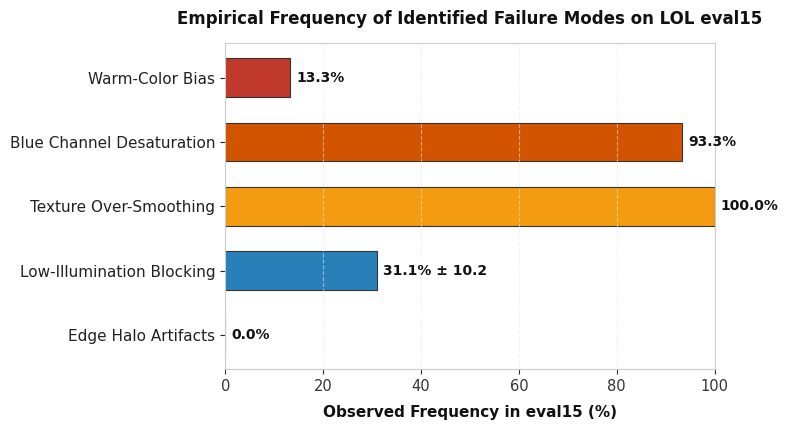


--- Config B (trung bình 3 seed) -> /content/LLFormer/results/fig_failure_modes_B.png


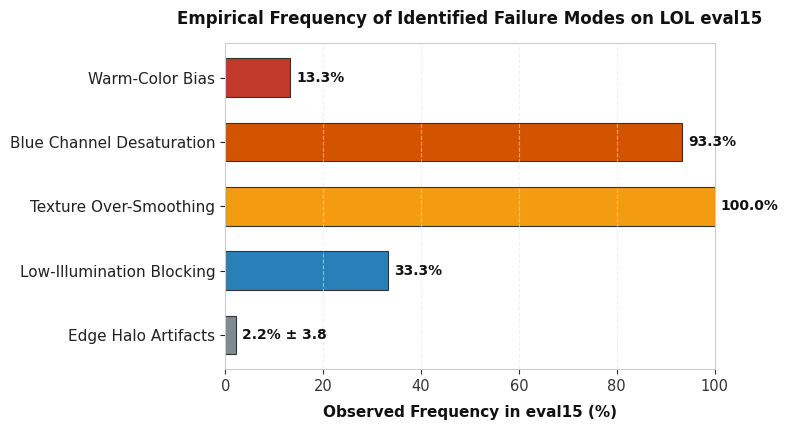


--- Config C (trung bình 3 seed) -> /content/LLFormer/results/fig_failure_modes_C.png


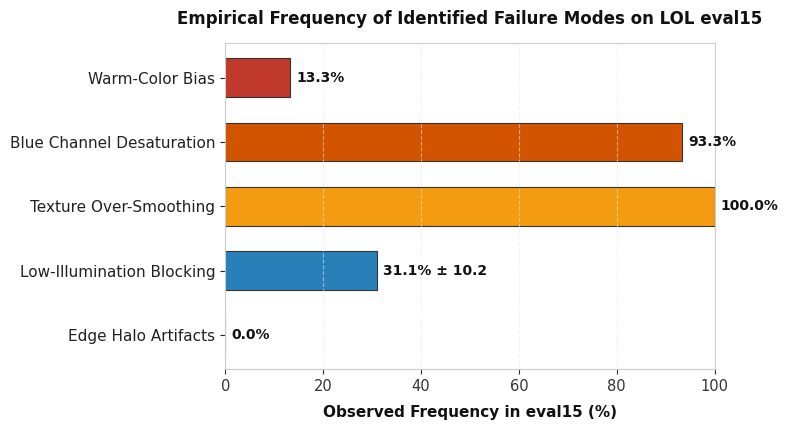


--- Config D (trung bình 3 seed) -> /content/LLFormer/results/fig_failure_modes_D.png


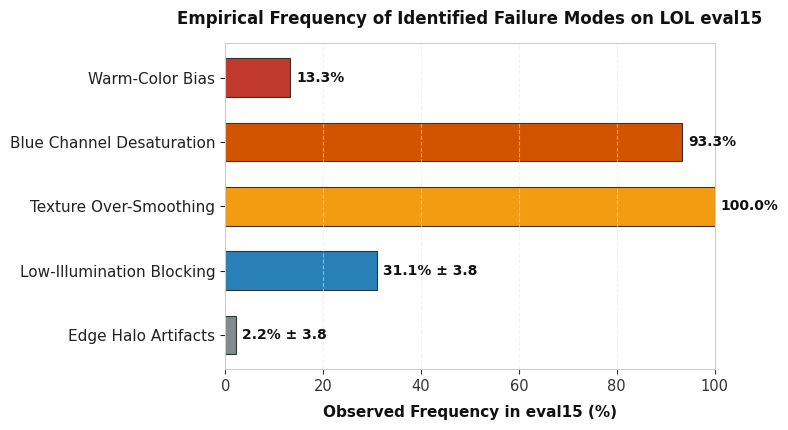


[OK] Đã sao lưu hình lên Drive.


In [ ]:
# ═══ 12D (bản sửa). Failure-mode: cùng luật ngưỡng + cùng KIỂU HÌNH với Fig. 9 trong paper ═══
import os, sys, importlib
import numpy as np, pandas as pd, cv2
from PIL import Image
import skimage.color as skc
import matplotlib.pyplot as plt

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import eval as ev
importlib.reload(ev)
OUT_ROOT = os.path.join(RESULTS_ROOT, 'paper_outputs')
PAIRS    = ev.find_pairs(VAL_DIR)
def _img(path):
    return np.array(Image.open(path).convert('RGB'))

MODES  = ['Warm-Color Bias', 'Blue Channel Desaturation', 'Texture Over-Smoothing',
          'Low-Illumination Blocking', 'Edge Halo Artifacts']
COLORS = ['#c0392b', '#d35400', '#f39c12', '#2980b9', '#7f8c8d']       # đúng màu Fig. 9 gốc
PAPER_FIG9 = dict(zip(MODES, [13.3, 93.3, 100.0, 46.7, 0.0]))          # số trong paper hiện tại (notebook 1)

def detect(gt_u8, pr_u8):
    """Luật ngưỡng THỦ CÔNG, giữ nguyên như notebook 1 (cần nêu rõ trong paper)."""
    g, p = gt_u8.astype(np.float32) / 255.0, pr_u8.astype(np.float32) / 255.0
    hg, hp = skc.rgb2hsv(g), skc.rgb2hsv(p)
    gg, gp = skc.rgb2gray(g).astype(np.float32), skc.rgb2gray(p).astype(np.float32)
    warm = bool((np.mean(p[..., 0] - p[..., 2]) - np.mean(g[..., 0] - g[..., 2])) > 0.015)
    blue = (hg[..., 0] >= 0.45) & (hg[..., 0] <= 0.75) & (hg[..., 1] > 0.15)
    if np.sum(blue) > 100:
        bd = bool(np.mean(hp[..., 1][blue]) < np.mean(hg[..., 1][blue]) * 0.90)
    else:
        bd = bool(np.mean(p[..., 2]) < np.mean(g[..., 2]) * 0.88)
    smooth = bool(cv2.Laplacian(gp, cv2.CV_32F).var() < cv2.Laplacian(gg, cv2.CV_32F).var() * 0.85)
    dark = gg < 0.15
    block = bool(np.mean(np.abs(p[dark] - g[dark])) > 0.08) if np.sum(dark) > 500 else False
    sob = np.hypot(cv2.Sobel(gg, cv2.CV_32F, 1, 0), cv2.Sobel(gg, cv2.CV_32F, 0, 1))
    em = sob > np.percentile(sob, 85)
    halo = bool((np.mean(np.abs(gp[em] - gg[em])) - np.mean(np.abs(gp - gg))) > 0.035)
    return dict(zip(MODES, (warm, bd, smooth, block, halo)))

# ---- 1) Chạy bộ phát hiện trên ảnh epoch cuối của mọi (config, seed) ----
recs = []
for c in 'ABCD':
    for s in SEEDS:
        folder = f'{ev.FOLDERS[c]}_s{s}'
        d = os.path.join(OUT_ROOT, folder)
        if not all(os.path.isfile(os.path.join(d, f'{n}.png')) for n, _, _ in PAIRS):
            print(f'[THIẾU ảnh] {folder} (chạy cell 12B)'); continue
        for n, _, hp in PAIRS:
            recs.append(dict(config=c, seed=s, image=n, **detect(_img(hp), _img(os.path.join(d, f'{n}.png')))))
df = pd.DataFrame(recs)
df.to_csv(os.path.join(RESULTS_ROOT, 'failure_modes_per_image_ABCD.csv'), index=False)

# tần suất (% ảnh eval15) cho từng run -> mean ± std qua seed
per_run = df.groupby(['config', 'seed'])[MODES].mean() * 100.0
mean_by = per_run.groupby('config').mean()
std_by  = per_run.groupby('config').std()          # NaN nếu chỉ có 1 seed
cfgs    = [c for c in 'ABCD' if c in mean_by.index]

lines = ['| Config | n seed | ' + ' | '.join(MODES) + ' |', '|' + '---|' * (len(MODES) + 2)]
for c in cfgs:
    cells = [f'{mean_by.loc[c, m]:.1f} ± {std_by.loc[c, m]:.1f}' if std_by.loc[c, m] == std_by.loc[c, m] else f'{mean_by.loc[c, m]:.1f}' for m in MODES]
    lines.append(f'| {c} | {int((per_run.reset_index().config == c).sum())} | ' + ' | '.join(cells) + ' |')
txt = '### Tần suất failure-mode (% ảnh eval15; mean ± std qua seed)\n\n' + '\n'.join(lines)
print(txt)
if 'A' in cfgs:
    print('\nSo với số trong paper hiện tại (notebook 1: epoch tốt nhất, 1 lần chạy):')
    for m in MODES:
        print(f'  {m:<28} paper {PAPER_FIG9[m]:>5.1f}% | Config A mới (epoch cuối, TB {len(SEEDS)} seed) {mean_by.loc["A", m]:>5.1f}%')
with open(os.path.join(RESULTS_ROOT, 'failure_modes_summary_ABCD.md'), 'w', encoding='utf-8') as f:
    f.write(txt + '\n')

# ---- 2) Hình KIỂU Fig. 9 của paper (barh ngang, cùng màu/cỡ/tiêu đề) cho từng config ----
def plot_fig9(cfg, save_path, show=True):
    mu = [mean_by.loc[cfg, m] for m in MODES]
    sd = [std_by.loc[cfg, m] for m in MODES]
    fig, ax = plt.subplots(figsize=(8.0, 4.4), facecolor='#ffffff')
    ax.set_facecolor('#ffffff')
    bars = ax.barh(MODES[::-1], mu[::-1], color=COLORS[::-1], height=0.6, edgecolor='#333333', linewidth=0.8)
    for bar, s_ in zip(bars, sd[::-1]):
        w = bar.get_width()
        lab = f'{w:.1f}%' + (f' ± {s_:.1f}' if (s_ == s_ and s_ > 0.05) else '')   # chỉ thêm ± khi các seed khác nhau
        ax.text(w + 1.2, bar.get_y() + bar.get_height() / 2.0, lab, va='center', ha='left',
                fontsize=10, fontweight='bold', color='#111111')
    ax.set_xlim(0, 100)
    ax.set_xlabel('Observed Frequency in eval15 (%)', fontsize=11, fontweight='bold', color='#111111', labelpad=8)
    ax.set_title('Empirical Frequency of Identified Failure Modes on LOL eval15',
                 fontsize=12, fontweight='bold', color='#111111', pad=14)
    ax.grid(axis='x', linestyle='--', alpha=0.55, color='#e2e8f0')
    ax.tick_params(axis='y', colors='#222222', labelsize=11)
    ax.tick_params(axis='x', colors='#333333', labelsize=10.5)
    for spine in ax.spines.values():
        spine.set_color('#cccccc'); spine.set_linewidth(0.8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='#ffffff')
    if show: plt.show()
    else: plt.close(fig)

for c in cfgs:
    p = os.path.join(RESULTS_ROOT, f'fig_failure_modes_{c}.png')
    print(f'\n--- Config {c} (trung bình {int((per_run.reset_index().config == c).sum())} seed) -> {p}')
    with plt.rc_context({'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'], 'axes.grid': False}):
        plot_fig9(c, p)
if SAVE_TO_DRIVE:
    import shutil
    os.makedirs(os.path.join(DRIVE_ROOT, 'results'), exist_ok=True)
    for c in cfgs:
        shutil.copy2(os.path.join(RESULTS_ROOT, f'fig_failure_modes_{c}.png'), os.path.join(DRIVE_ROOT, 'results'))
    print('\n[OK] Đã sao lưu hình lên Drive.')

## Section 13: Export Checkpoints and Logs

Đóng gói toàn bộ kết quả và tải về máy tính hoặc sao lưu lên Drive.


In [ ]:
import shutil, os, zipfile
from pathlib import Path

# Tao file ZIP chua ket qua (BO QUA *.pth: moi checkpoint ~300 MB, 12 run se thanh vai GB)
results_zip = '/content/LLFormer_Results_ABCD.zip'
n_files = 0
with zipfile.ZipFile(results_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(RESULTS_ROOT):
        for fn in files:
            if fn.endswith(('.pth', '.tmp')):
                continue
            full = os.path.join(root, fn)
            zf.write(full, os.path.relpath(full, RESULTS_ROOT))
            n_files += 1
size_mb = os.path.getsize(results_zip) / 1e6
print(f'[OK] Da tao: {results_zip} ({n_files} file, {size_mb:.1f} MB, khong gom checkpoint)')

# Sao luu len Drive
if SAVE_TO_DRIVE:
    dst = os.path.join(DRIVE_ROOT, 'LLFormer_Results_ABCD.zip')
    shutil.copy2(results_zip, dst)
    print(f'[OK] Da sao luu len Drive: {dst}')

# Tai ve may tinh
try:
    from google.colab import files
    print('Bat dau tai file ve may tinh...')
    files.download(results_zip)
except Exception as e:
    print(f'Khong the tai tu dong ({e}).')
    print(f'Hay tai thu cong tu: {results_zip}')


Training log  : ['A', 'B', 'C', 'D']
Per-image eval: ['A', 'B', 'C', 'D']


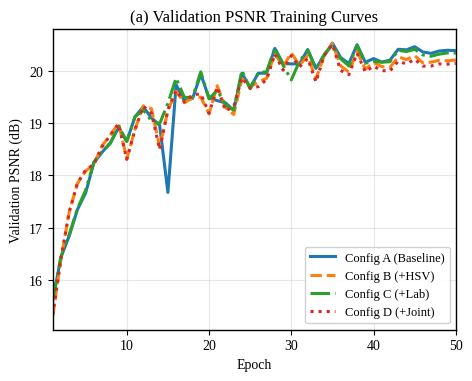

  [OK] fig1_training_curves_psnr


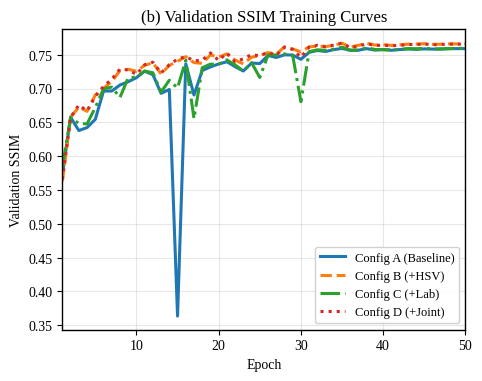

  [OK] fig2_training_curves_ssim


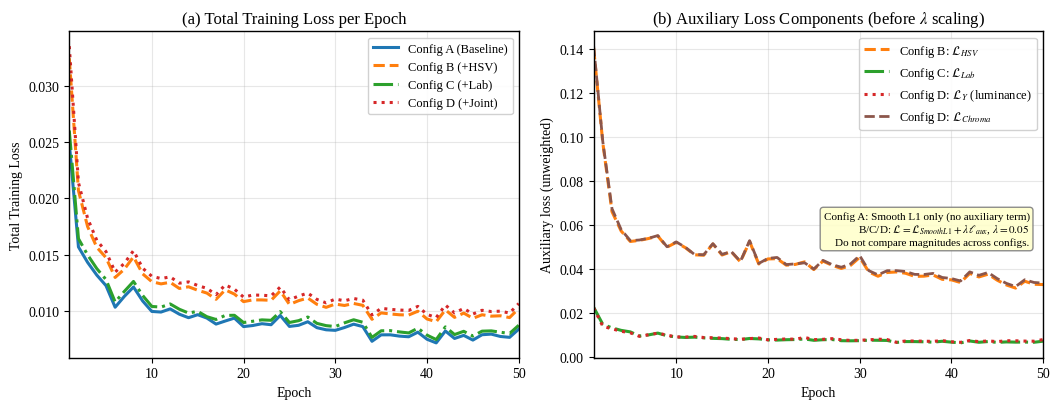

  [OK] fig3_loss_components


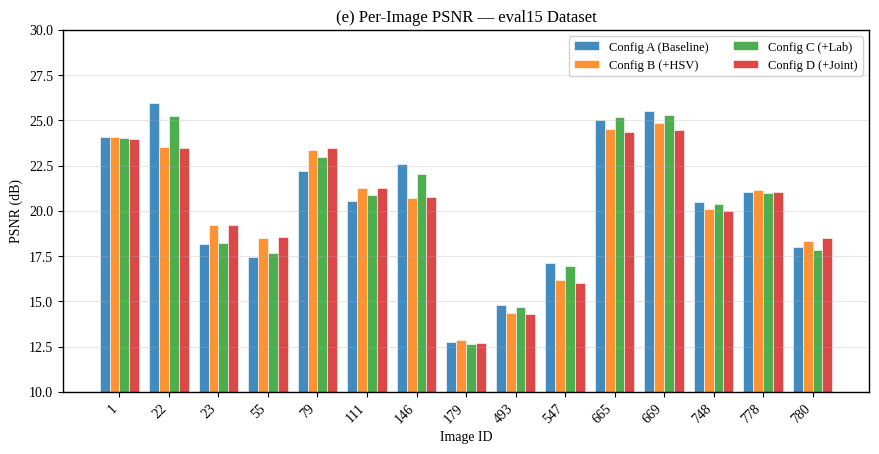

  [OK] fig4_per_image_psnr


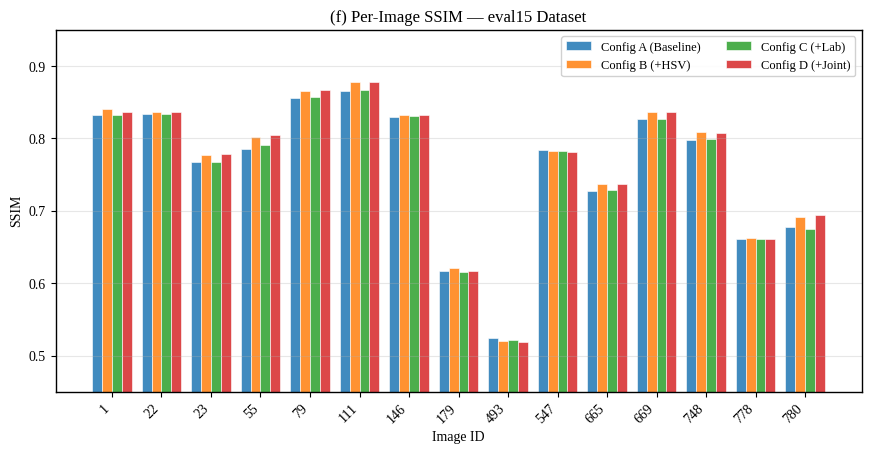

  [OK] fig5_per_image_ssim


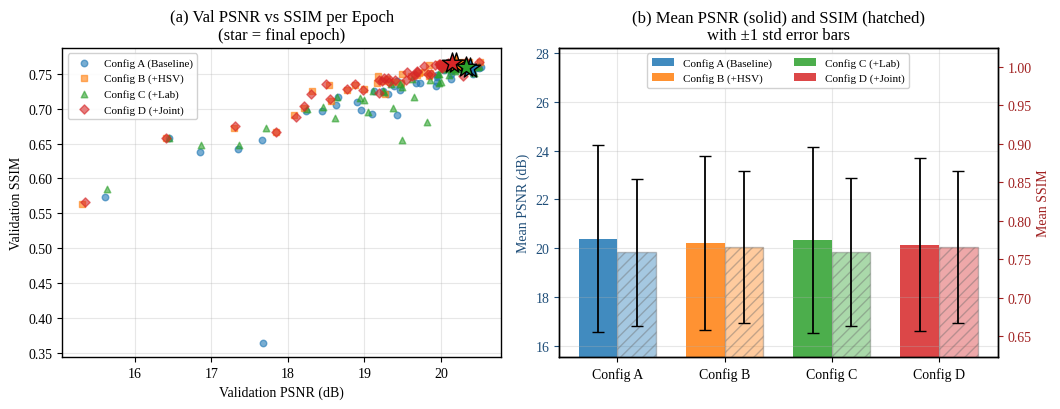

  [OK] fig6_psnr_ssim_comparison


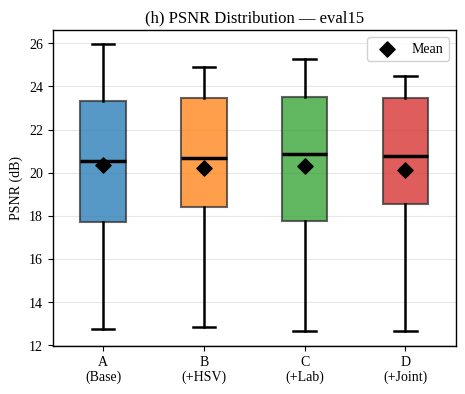

  [OK] fig7_psnr_distribution


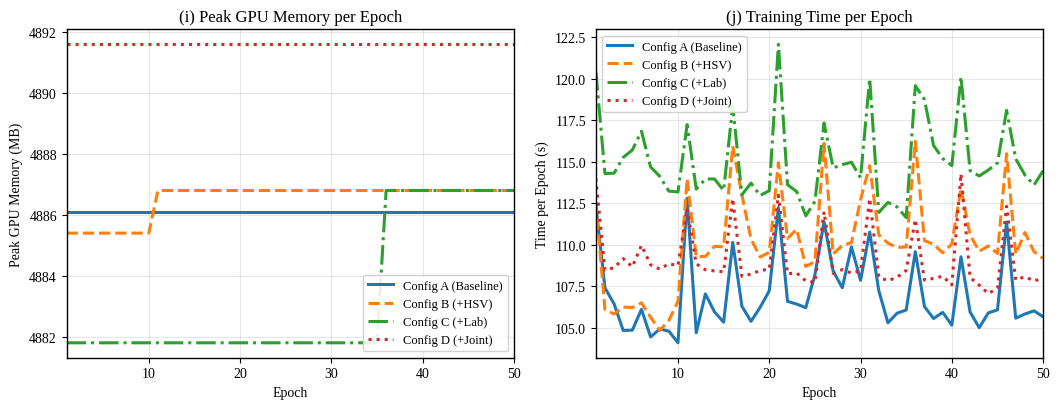

  [OK] fig8_vram_time


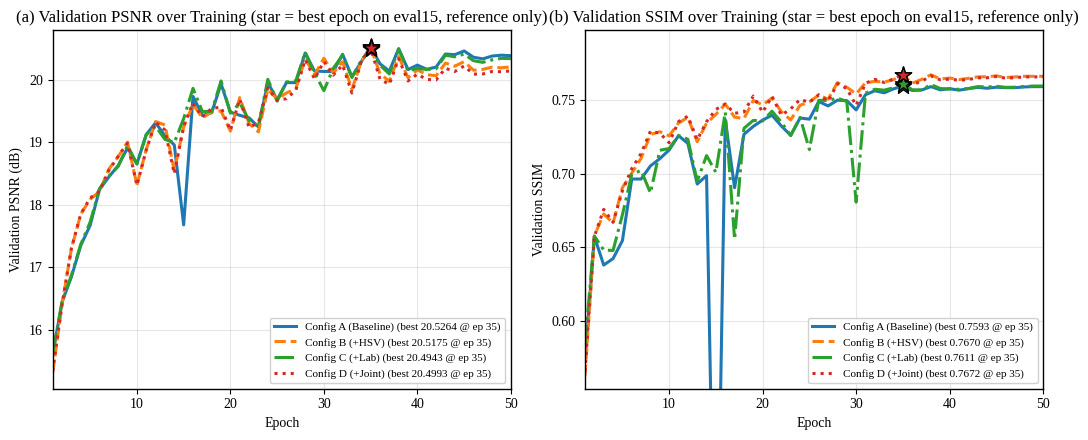

  [OK] fig9_combined_summary


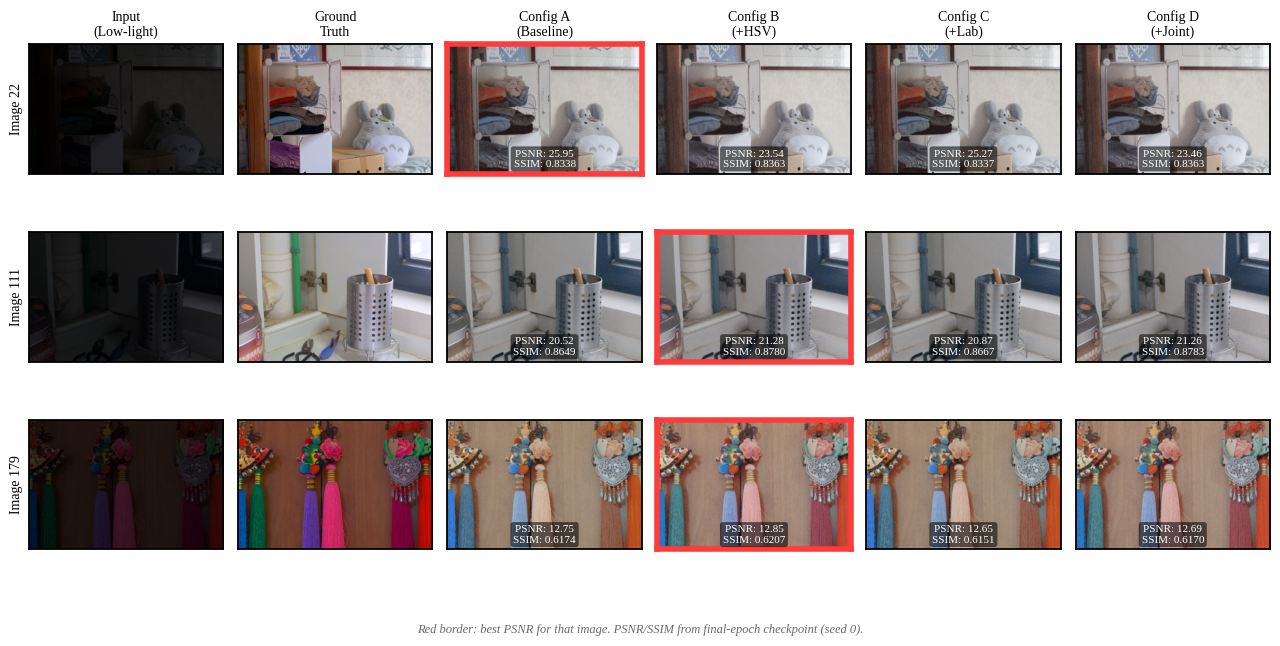

  [OK] fig10_visual_comparison


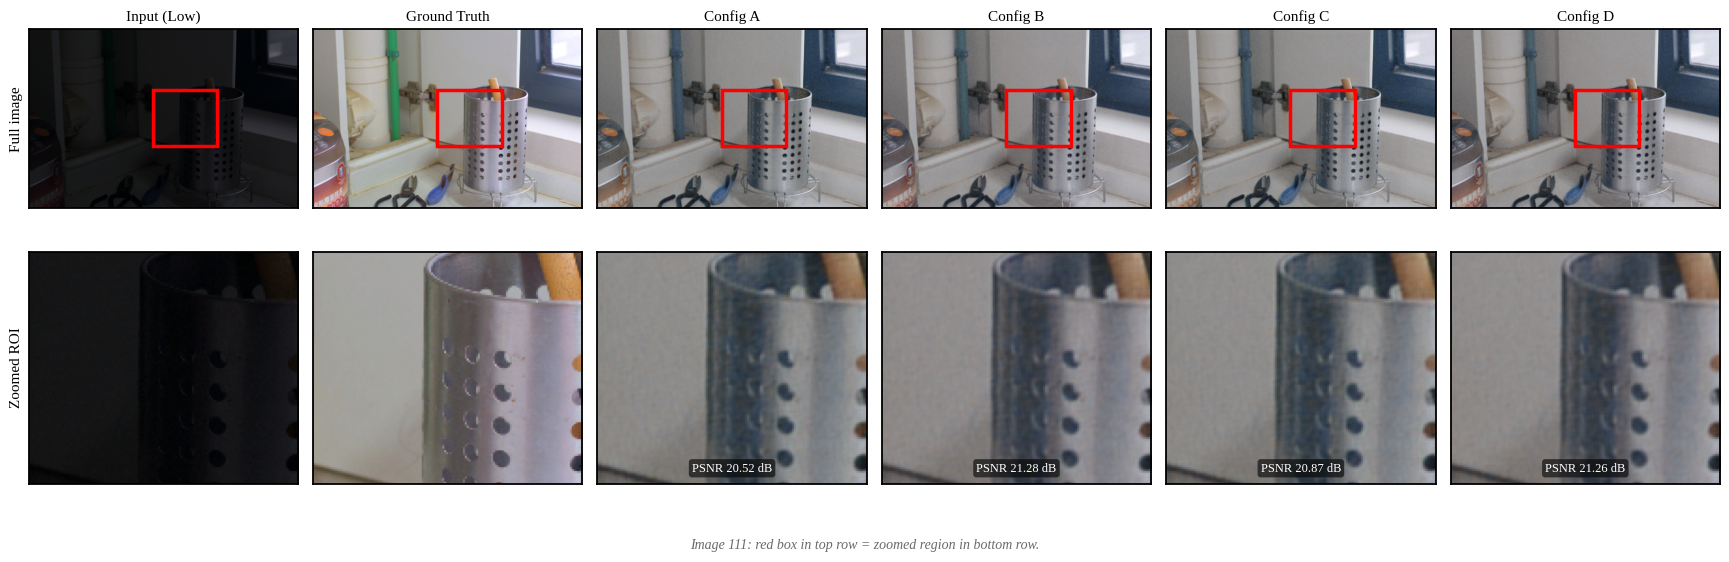

  [OK] fig11_zoomed_patch

[OK] Hinh luu tai: /content/LLFormer/results/paper_figures
[OK] Da sao luu len Drive: /content/drive/MyDrive/LLFormer1/LLFormer_Colab/paper_figures  (+ paper_figures.zip)


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 14: PAPER FIGURES (Fig 1–11) — đọc dữ liệu thật từ results/, không tự tạo số liệu
# ═══════════════════════════════════════════════════════════════════════════
import warnings, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image
warnings.filterwarnings('ignore')

FIG_SEED = SEEDS[0]   # hinh ve tu MOT seed; thong ke da-seed nam o bang Section 12
CFG   = {'A': f'A_baseline_s{FIG_SEED}', 'B': f'B_hsv_s{FIG_SEED}', 'C': f'C_lab_s{FIG_SEED}', 'D': f'D_joint_s{FIG_SEED}'}
LABEL = {'A': 'Config A (Baseline)', 'B': 'Config B (+HSV)',
         'C': 'Config C (+Lab)',     'D': 'Config D (+Joint)'}
SHORT = {'A': 'A\n(Base)', 'B': 'B\n(+HSV)', 'C': 'C\n(+Lab)', 'D': 'D\n(+Joint)'}
COLOR = {'A': '#1f77b4', 'B': '#ff7f0e', 'C': '#2ca02c', 'D': '#d62728'}
LS    = {'A': '-', 'B': '--', 'C': '-.', 'D': ':'}
MARK  = {'A': 'o', 'B': 's', 'C': '^', 'D': 'D'}

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.linewidth': 1.0,
    'axes.grid': True, 'grid.alpha': 0.3, 'legend.framealpha': 0.9,
    'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

FIG_DIR = Path(RESULTS_ROOT) / 'paper_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Tìm file: ưu tiên local, không có thì lấy từ Drive ─────────────────────
def get_path(k, rel):
    cands = [Path(RESULTS_ROOT) / CFG[k] / rel]
    if SAVE_TO_DRIVE:
        cands.append(Path(DRIVE_ROOT) / 'results' / CFG[k] / rel)
    for p in cands:
        if p.exists():
            return p
    return None

def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(FIG_DIR / f'{name}.{ext}')
    plt.show(); plt.close(fig)
    print(f'  [OK] {name}')

# ── Load dữ liệu ───────────────────────────────────────────────────────────
logs, per = {}, {}
for k in CFG:
    p = get_path(k, 'training_log.csv')
    if p: logs[k] = pd.read_csv(p)
    p = get_path(k, 'per_image_metrics.csv')
    if p:
        d = pd.read_csv(p)
        d['id'] = d['filename'].astype(str).map(lambda s: Path(s).stem)
        per[k] = d.set_index('id')

print('Training log  :', list(logs))
print('Per-image eval:', list(per))
if not logs:
    raise FileNotFoundError('Chua co training_log.csv nao. Hay train it nhat 1 config truoc.')

def id_key(s):
    return (0, int(s)) if str(s).isdigit() else (1, str(s))

common_ids = None
for d in per.values():
    common_ids = set(d.index) if common_ids is None else common_ids & set(d.index)
IDS = sorted(common_ids, key=id_key) if common_ids else []

# ═════════════ Fig 1, 2 — Validation curves ═════════════
def curve_fig(metric, ylabel, title, name):
    fig, ax = plt.subplots(figsize=(5.2, 3.9))
    for k, df in logs.items():
        ax.plot(df['epoch'], df[metric], color=COLOR[k], ls=LS[k], lw=2.2, label=LABEL[k])
    ax.set_xlim(1, max(df['epoch'].max() for df in logs.values()))
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(loc='lower right', fontsize=9)
    save(fig, name)

curve_fig('val_psnr', 'Validation PSNR (dB)', '(a) Validation PSNR Training Curves', 'fig1_training_curves_psnr')
curve_fig('val_ssim', 'Validation SSIM',      '(b) Validation SSIM Training Curves', 'fig2_training_curves_ssim')

# ═════════════ Fig 3 — Loss components ═════════════
fig, axs = plt.subplots(1, 2, figsize=(10.7, 4.2))
for k, df in logs.items():
    axs[0].plot(df['epoch'], df['train_loss'], color=COLOR[k], ls=LS[k], lw=2.2, label=LABEL[k])
axs[0].set_title('(a) Total Training Loss per Epoch')
axs[0].set_ylabel('Total Training Loss')
for k, df in logs.items():
    if k == 'A':
        continue  # Config A khong co thanh phan phu (aux = 0)
    lab = {'B': r'Config B: $\mathcal{L}_{HSV}$', 'C': r'Config C: $\mathcal{L}_{Lab}$',
           'D': r'Config D: $\mathcal{L}_{Y}$ (luminance)'}[k]
    axs[1].plot(df['epoch'], df['l_aux1'], color=COLOR[k], ls=LS[k], lw=2.2, label=lab)
    if k == 'D':
        axs[1].plot(df['epoch'], df['l_aux2'], color='#8c564b', ls='--', lw=2.0,
                    label=r'Config D: $\mathcal{L}_{Chroma}$')
axs[1].set_title(r'(b) Auxiliary Loss Components (before $\lambda$ scaling)')
axs[1].set_ylabel('Auxiliary loss (unweighted)')
axs[1].legend(loc='upper right', fontsize=9)
axs[1].text(0.97, 0.45,
            'Config A: Smooth L1 only (no auxiliary term)\n'
            r'B/C/D: $\mathcal{L}=\mathcal{L}_{SmoothL1}+\lambda\,\ell_{aux}$, $\lambda=0.05$'
            '\nDo not compare magnitudes across configs.',
            transform=axs[1].transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round', fc='#ffffcc', ec='gray', alpha=0.9))
for ax in axs:
    ax.set_xlabel('Epoch')
    ax.set_xlim(1, max(df['epoch'].max() for df in logs.values()))
axs[0].legend(loc='upper right', fontsize=9)
fig.tight_layout()
save(fig, 'fig3_loss_components')

# ═════════════ Fig 4, 5 — Per-image PSNR / SSIM (grouped bar) ═════════════
def per_image_bar(metric, ylabel, title, name, floor_step):
    ks = [k for k in CFG if k in per]
    fig, ax = plt.subplots(figsize=(10.4, 4.7))
    x, w = np.arange(len(IDS)), 0.8 / len(ks)
    for i, k in enumerate(ks):
        ax.bar(x + (i - (len(ks) - 1) / 2) * w, per[k].loc[IDS, metric].values, w,
               color=COLOR[k], alpha=0.85, edgecolor='white', lw=0.5, label=LABEL[k])
    allv = np.concatenate([per[k].loc[IDS, metric].values for k in ks])
    ax.set_ylim(np.floor(allv.min() / floor_step) * floor_step - floor_step,
                np.ceil(allv.max() / floor_step) * floor_step + floor_step)
    ax.set_xticks(x); ax.set_xticklabels(IDS, rotation=45, ha='right')
    ax.set_xlabel('Image ID'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper right', ncol=2, fontsize=9)
    save(fig, name)

if IDS:
    per_image_bar('psnr', 'PSNR (dB)', '(e) Per-Image PSNR — eval15 Dataset', 'fig4_per_image_psnr', 2.5)
    per_image_bar('ssim', 'SSIM',      '(f) Per-Image SSIM — eval15 Dataset', 'fig5_per_image_ssim', 0.05)

# ═════════════ Fig 6 — PSNR–SSIM scatter + mean bar ═════════════
fig, axs = plt.subplots(1, 2, figsize=(10.7, 4.2))
for k, df in logs.items():
    axs[0].scatter(df['val_psnr'], df['val_ssim'], c=COLOR[k], marker=MARK[k],
                   s=22, alpha=0.6, label=LABEL[k], zorder=2)
for k, df in logs.items():  # sao = epoch cuoi
    axs[0].scatter(df['val_psnr'].iloc[-1], df['val_ssim'].iloc[-1], c=COLOR[k],
                   marker='*', s=230, edgecolor='black', lw=1.0, zorder=5)
axs[0].set_xlabel('Validation PSNR (dB)'); axs[0].set_ylabel('Validation SSIM')
axs[0].set_title('(a) Val PSNR vs SSIM per Epoch\n(star = final epoch)')
axs[0].legend(loc='upper left', fontsize=8)

ks = [k for k in CFG if k in per]
if ks:
    ax, ax2 = axs[1], axs[1].twinx()
    ax2.grid(False)
    pm = [per[k]['psnr'].mean() for k in ks]; ps = [per[k]['psnr'].std(ddof=0) for k in ks]
    sm = [per[k]['ssim'].mean() for k in ks]; ss = [per[k]['ssim'].std(ddof=0) for k in ks]
    x = np.arange(len(ks)); w = 0.36
    for i, k in enumerate(ks):
        ax.bar(x[i] - w / 2, pm[i], w, color=COLOR[k], alpha=0.85)
        ax2.bar(x[i] + w / 2, sm[i], w, color=COLOR[k], alpha=0.40, hatch='///', edgecolor='dimgray')
    ax.errorbar(x - w / 2,  pm, yerr=ps, fmt='none', ecolor='black', capsize=4, lw=1.3, zorder=6)
    ax2.errorbar(x + w / 2, sm, yerr=ss, fmt='none', ecolor='black', capsize=4, lw=1.3, zorder=6)
    ax.set_ylim(min(np.subtract(pm, ps)) - 1, max(np.add(pm, ps)) + 4)
    ax2.set_ylim(min(np.subtract(sm, ss)) - 0.04, max(np.add(sm, ss)) + 0.16)
    ax.set_xticks(x); ax.set_xticklabels([f'Config {k}' for k in ks])
    ax.set_ylabel('Mean PSNR (dB)', color='#1f4e79'); ax2.set_ylabel('Mean SSIM', color='#a02020')
    ax.tick_params(axis='y', colors='#1f4e79'); ax2.tick_params(axis='y', colors='#a02020')
    ax.set_title('(b) Mean PSNR (solid) and SSIM (hatched)\nwith ±1 std error bars')
    ax.legend(handles=[Patch(fc=COLOR[k], alpha=0.85, label=LABEL[k]) for k in ks],
              loc='upper center', ncol=2, fontsize=8)
fig.tight_layout()
save(fig, 'fig6_psnr_ssim_comparison')

# ═════════════ Fig 7 — PSNR distribution (boxplot) ═════════════
if ks:
    fig, ax = plt.subplots(figsize=(5.2, 4.1))
    data = [per[k]['psnr'].values for k in ks]
    bp = ax.boxplot(data, widths=0.45, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', lw=2.5),
                    whiskerprops=dict(lw=1.8), capprops=dict(lw=1.8),
                    boxprops=dict(lw=1.5, ec='#333333'))
    for patch, k in zip(bp['boxes'], ks):
        patch.set_facecolor(COLOR[k]); patch.set_alpha(0.75)
    ax.scatter(range(1, len(ks) + 1), [d.mean() for d in data], marker='D', s=60,
               c='black', zorder=5, label='Mean')
    ax.set_xticks(range(1, len(ks) + 1)); ax.set_xticklabels([SHORT[k] for k in ks])
    ax.set_ylabel('PSNR (dB)'); ax.set_title('(h) PSNR Distribution — eval15')
    ax.grid(axis='x', visible=False); ax.legend(loc='upper right')
    save(fig, 'fig7_psnr_distribution')

# ═════════════ Fig 8 — VRAM & thời gian mỗi epoch ═════════════
fig, axs = plt.subplots(1, 2, figsize=(10.7, 4.2))
for k, df in logs.items():
    axs[0].plot(df['epoch'], df['peak_vram_mb'], color=COLOR[k], ls=LS[k], lw=2.2, label=LABEL[k])
    axs[1].plot(df['epoch'], df['time_sec'],     color=COLOR[k], ls=LS[k], lw=2.2, label=LABEL[k])
axs[0].set_title('(i) Peak GPU Memory per Epoch'); axs[0].set_ylabel('Peak GPU Memory (MB)')
axs[1].set_title('(j) Training Time per Epoch');   axs[1].set_ylabel('Time per Epoch (s)')
for ax in axs:
    ax.set_xlabel('Epoch'); ax.legend(fontsize=9)
    ax.set_xlim(1, max(df['epoch'].max() for df in logs.values()))
fig.tight_layout()
save(fig, 'fig8_vram_time')

# ═════════════ Fig 9 — Combined PSNR + SSIM (đánh dấu epoch tốt nhất) ═════════════
fig, axs = plt.subplots(1, 2, figsize=(10.7, 4.5))
for ax, metric, ylab, title in [(axs[0], 'val_psnr', 'Validation PSNR (dB)', '(a) Validation PSNR over Training (star = best epoch on eval15, reference only)'),
                                (axs[1], 'val_ssim', 'Validation SSIM',     '(b) Validation SSIM over Training (star = best epoch on eval15, reference only)')]:
    for k, df in logs.items():
        bi = df[metric].idxmax()
        ax.plot(df['epoch'], df[metric], color=COLOR[k], ls=LS[k], lw=2.2,
                label=f"{LABEL[k]} (best {df.loc[bi, metric]:.4f} @ ep {int(df.loc[bi, 'epoch'])})")
        ax.scatter(df.loc[bi, 'epoch'], df.loc[bi, metric], marker='*', s=150,
                   c=COLOR[k], edgecolor='black', zorder=5)
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylab); ax.set_title(title)
    ax.set_xlim(1, max(df['epoch'].max() for df in logs.values()))
    ax.legend(loc='lower right', fontsize=8)
allssim = np.concatenate([df['val_ssim'].values for df in logs.values()])
axs[1].set_ylim(max(0.3, np.percentile(allssim, 2) - 0.03), min(1.0, allssim.max() + 0.03))
fig.tight_layout()
save(fig, 'fig9_combined_summary')

# ═════════════ Fig 10, 11 — So sánh ảnh khôi phục ═════════════
def find_img(folder, name):
    for ext in ('.png', '.jpg', '.jpeg', '.bmp'):
        p = Path(folder) / f'{name}{ext}'
        if p.exists():
            return p
    return None

def load_img(p):
    return np.asarray(Image.open(p).convert('RGB'))

ref = 'A' if 'A' in per else (ks[0] if ks else None)
if ref is None:
    print('[SKIP] Fig 10/11: chua co per_image_metrics.csv')
else:
    order = per[ref].loc[IDS, 'psnr'].sort_values(ascending=False).index.tolist()
    reps = [order[0], order[len(order) // 2], order[-1]]   # PSNR cao / trung binh / thap

    def load_set(img_id):
        s = {'Input (Low-light)': find_img(Path(VAL_DIR) / 'low', img_id),
             'Ground Truth':      find_img(Path(VAL_DIR) / 'high', img_id)}
        for k in ks:
            s[k] = get_path(k, f'restored_images/{img_id}.png')
        return s

    # ── Fig 10 ──
    cols = ['Input\n(Low-light)', 'Ground\nTruth'] + [LABEL[k].replace(' (', '\n(') for k in ks]
    fig, axs = plt.subplots(len(reps), len(cols), figsize=(2.15 * len(cols), 2.0 * len(reps) + 0.6))
    axs = np.atleast_2d(axs)
    ok10 = True
    for r, img_id in enumerate(reps):
        paths = load_set(img_id)
        if any(p is None for p in paths.values()):
            print(f'[SKIP] Fig 10: thieu anh cho Image {img_id}'); ok10 = False; break
        best_k = max(ks, key=lambda k: per[k].loc[img_id, 'psnr'])
        items = [paths['Input (Low-light)'], paths['Ground Truth']] + [paths[k] for k in ks]
        for c, p in enumerate(items):
            ax = axs[r, c]; ax.imshow(load_img(p)); ax.grid(False)
            ax.set_xticks([]); ax.set_yticks([])
            is_best = c >= 2 and ks[c - 2] == best_k
            for sp in ax.spines.values():
                sp.set_edgecolor('#ff3b3b' if is_best else 'black')
                sp.set_linewidth(4 if is_best else 1.3)
            if c >= 2:
                k = ks[c - 2]
                ax.text(0.5, 0.04, f"PSNR: {per[k].loc[img_id, 'psnr']:.2f}\nSSIM: {per[k].loc[img_id, 'ssim']:.4f}",
                        transform=ax.transAxes, ha='center', va='bottom', color='white', fontsize=8,
                        bbox=dict(boxstyle='round,pad=0.25', fc='black', alpha=0.55, ec='none'))
            if r == 0:
                ax.set_title(cols[c], fontsize=10)
        axs[r, 0].set_ylabel(f'Image {img_id}', fontsize=10)
    if ok10:
        fig.text(0.5, 0.0, f'Red border: best PSNR for that image. PSNR/SSIM from final-epoch checkpoint (seed {FIG_SEED}).',
                 ha='center', style='italic', fontsize=9, color='dimgray')
        fig.tight_layout(rect=(0, 0.03, 1, 1))
        save(fig, 'fig10_visual_comparison')
    else:
        plt.close(fig)

    # ── Fig 11: zoom ROI ── (đổi ZOOM_ID / ZOOM_BOX nếu muốn chọn ảnh/vùng khác)
    ZOOM_ID  = reps[1]                       # ví dụ: '748'
    ZOOM_BOX = (0.46, 0.34, 0.24, 0.31)      # (x, y, rộng, cao) theo tỷ lệ ảnh [0..1]
    paths = load_set(ZOOM_ID)
    if any(p is None for p in paths.values()):
        print(f'[SKIP] Fig 11: thieu anh cho Image {ZOOM_ID}')
    else:
        items = [paths['Input (Low-light)'], paths['Ground Truth']] + [paths[k] for k in ks]
        titles = ['Input (Low)', 'Ground Truth'] + [f'Config {k}' for k in ks]
        gt = load_img(paths['Ground Truth']); H, W = gt.shape[:2]
        x0, y0 = int(ZOOM_BOX[0] * W), int(ZOOM_BOX[1] * H)
        x1, y1 = x0 + int(ZOOM_BOX[2] * W), y0 + int(ZOOM_BOX[3] * H)
        fig, axs = plt.subplots(2, len(items), figsize=(2.9 * len(items), 6.0))
        for c, p in enumerate(items):
            im = np.asarray(Image.fromarray(load_img(p)).resize((W, H)))
            axs[0, c].imshow(im)
            axs[0, c].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='red', lw=2.5))
            axs[1, c].imshow(im[y0:y1, x0:x1])
            axs[0, c].set_title(titles[c], fontsize=11)
            if c >= 2:
                axs[1, c].text(0.5, 0.04, f"PSNR {per[ks[c - 2]].loc[ZOOM_ID, 'psnr']:.2f} dB",
                               transform=axs[1, c].transAxes, ha='center', va='bottom', color='white',
                               fontsize=9, bbox=dict(boxstyle='round,pad=0.25', fc='black', alpha=0.6, ec='none'))
            for r in range(2):
                axs[r, c].grid(False); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
                for sp in axs[r, c].spines.values():
                    sp.set_linewidth(1.3)
        axs[0, 0].set_ylabel('Full image', fontsize=11); axs[1, 0].set_ylabel('Zoomed ROI', fontsize=11)
        fig.text(0.5, 0.01, f'Image {ZOOM_ID}: red box in top row = zoomed region in bottom row.',
                 ha='center', style='italic', fontsize=10, color='dimgray')
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        save(fig, 'fig11_zoomed_patch')

# ═════════════ Sao lưu toàn bộ hình lên Drive ═════════════
print(f'\n[OK] Hinh luu tai: {FIG_DIR}')
if SAVE_TO_DRIVE:
    dst = Path(DRIVE_ROOT) / 'paper_figures'
    shutil.copytree(FIG_DIR, dst, dirs_exist_ok=True)
    shutil.make_archive(str(Path(DRIVE_ROOT) / 'paper_figures'), 'zip', FIG_DIR)
    print(f'[OK] Da sao luu len Drive: {dst}  (+ paper_figures.zip)')